# Phân tích dữ liệu Dunnhumby cho bài toán Customer Purchase Propensity

Một bộ phận CRM có thể cần sắp xếp thứ tự ưu tiên các hộ gia đình khi không đủ nguồn lực để liên hệ với tất cả mọi người. Trước khi dự báo, câu hỏi nền tảng là: **dữ liệu giao dịch có cho phép chúng ta quan sát lịch sử mua của từng hộ và xác định rõ điều gì xảy ra sau một thời điểm hay không?**

**Câu hỏi nghiên cứu:** Tại một thời điểm quan sát, lịch sử giao dịch cho biết điều gì về khả năng household phát sinh ít nhất một basket trong 7 ngày kế tiếp? Đây là bài toán dự báo hành vi được ghi nhận, chưa đo lường tác động của một thông điệp hay coupon.

**Lộ trình câu chuyện:** Kiểm tra dữ liệu có thể kết nối và được hiểu đúng → quan sát thời gian và hành vi từng hộ → xây dựng nhãn theo định nghĩa đã chọn → khảo sát các tín hiệu hành vi và bối cảnh → xác định giới hạn trước bước mô hình hóa.

**Phạm vi:** Phân tích nhãn và hành vi dùng snapshot ngày 180–537; nhãn trưởng thành tới ngày 544. Kiểm tra chất lượng nguồn và chuỗi thời gian dùng toàn bộ dữ liệu; biểu đồ 40 household dùng lịch sử đến ngày 537. Kết quả chỉ mô tả giao dịch được ghi nhận tại một retailer; dữ liệu không cho biết hộ có mua ở nơi khác hay không.

Đây là notebook **Data Understanding và EDA**. Phần tạo bảng cho mô hình và đánh giá nằm trong [notebook mô hình hóa](modeling_va_danh_gia_propensity.ipynb); hai notebook chạy độc lập.

## 1. Thiết lập và kiểm tra dữ liệu đầu vào

Chạy notebook từ thư mục gốc của project hoặc từ thư mục `notebooks`. Cần `pandas`, `numpy`, `matplotlib` và `IPython`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA = ROOT / 'sample_data' / 'dunnhumby'
if not DATA.is_dir():
    raise FileNotFoundError(f'Không tìm thấy thư mục dữ liệu: {DATA}')
pd.set_option('display.max_columns', 30)
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11})
print('Dữ liệu:', DATA)
import seaborn as sns
from matplotlib.ticker import PercentFormatter, FuncFormatter
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# Cùng một hệ màu và typography cho các biểu đồ EDA.
EDA_COLORS = {'blue':'#276984','teal':'#168b85','orange':'#c47a43',
              'dark':'#173746','muted':'#59717d','grid':'#e0e9ec'}
EDA_GROUP_COLORS = ['#b4c8cd','#78aeb0','#428f94','#276984','#163e61']
sns.set_theme(style='whitegrid',context='notebook',font_scale=1.03,
              rc={'axes.titleweight':'bold','axes.titlecolor':'#173746',
                  'axes.labelcolor':'#334e5b','grid.color':'#e0e9ec',
                  'axes.spines.top':False,'axes.spines.right':False})

def eda_rate_heatmap(ax, summary, row, col, title, xlabel, ylabel):
    """Tỷ lệ và số household-snapshot; chỉ ẩn ô có ít hơn 30 snapshot."""
    rates=summary.pivot(index=row,columns=col,values='purchase_rate')
    counts=summary.pivot(index=row,columns=col,values='household_snapshots').reindex(index=rates.index,columns=rates.columns)
    shown=rates.where(counts>=30)
    labels=np.empty(shown.shape,dtype=object)
    for i in range(len(shown.index)):
        for j in range(len(shown.columns)):
            count=counts.iloc[i,j]
            labels[i,j]=f'{shown.iloc[i,j]:.0%}\nn={int(count):,}' if pd.notna(shown.iloc[i,j]) else ''
    ax.set_facecolor('#edf2f4')
    sns.heatmap(shown,annot=labels,fmt='',vmin=0,vmax=1,
                cmap=sns.light_palette('#176b77',as_cmap=True),linewidths=1.4,linecolor='white',
                annot_kws={'fontsize':8},cbar_kws={'label':'Tỷ lệ mua tiếp','shrink':.8},ax=ax)
    for i in range(len(shown.index)):
        for j in range(len(shown.columns)):
            if pd.isna(shown.iloc[i,j]):
                count=counts.iloc[i,j]
                label='—' if pd.isna(count) or count==0 else f'n={int(count)}\n<30'
                ax.text(j+.5,i+.5,label,ha='center',va='center',fontsize=8,color='#71858c')
    ax.set(title=title,xlabel=xlabel,ylabel=ylabel)
    ax.tick_params(axis='both',length=0,labelrotation=0)


Dữ liệu: sample_data/dunnhumby


### 1.1. Dữ liệu có đủ bối cảnh để trả lời câu hỏi không?

Ta bắt đầu bằng inventory tám bảng: tìm định danh household, thời gian, basket và các bảng mô tả sản phẩm hoặc marketing. `causal_data` được đếm theo từng phần do kích thước lớn; chưa nối bảng này vào transaction.

In [2]:
paths = sorted(DATA.glob('*.csv'))
inventory, tables = [], {}
for path in paths:
    if path.name == 'causal_data.csv':
        count = sum(len(part) for part in pd.read_csv(path, usecols=['PRODUCT_ID'], chunksize=1_000_000))
        header = pd.read_csv(path, nrows=0)
        inventory.append({'bảng': path.stem, 'dòng': count, 'cột': len(header.columns), 'ghi chú': 'đếm theo chunks'})
    else:
        frame = pd.read_csv(path)
        tables[path.stem] = frame
        inventory.append({'bảng': path.stem, 'dòng': len(frame), 'cột': len(frame.columns), 'ghi chú': ''})
inventory = pd.DataFrame(inventory).sort_values('dòng', ascending=False)
display(inventory.reset_index(drop=True))

,bảng,dòng,cột,ghi chú
0,causal_data,36786524,5,đếm theo chunks
1,transaction_data,2595732,12,
2,coupon,124548,3,
3,product,92353,7,
4,campaign_table,7208,3,
5,coupon_redempt,2318,4,
6,hh_demographic,801,8,
7,campaign_desc,30,4,


**Điều quan sát được:** Transaction có 2.595.732 dòng; ngoài ra có bảng sản phẩm, demographic, campaign, coupon và media. Một dòng transaction là một sản phẩm trong basket, do đó không thể dùng số dòng làm số lần mua.

**Vì sao quan trọng?** Có thể theo dõi nhiều lần mua của cùng household và nối thêm bối cảnh sản phẩm. Tuy nhiên, `causal_data` ở cấp product–store–week, không phải tiếp xúc đã xác nhận của từng household. Trước khi dùng các quan hệ này, ta cần kiểm tra khóa và độ đầy đủ.

## 2. Có thể kết nối các bảng mà không làm sai số giao dịch?

Nếu một sản phẩm xuất hiện nhiều lần trong catalog, phép join có thể nhân bản dòng giao dịch. Nếu khóa thiếu hoặc không khớp, một phần hành vi có thể bị bỏ sót. Ta kiểm tra missing, duplicate và quan hệ giữa basket–household–product trước khi tổng hợp.

In [3]:
tx = tables['transaction_data'].copy()
product = tables['product']
demo = tables['hh_demographic']
redemption = tables['coupon_redempt']
print('Kích thước transaction:', tx.shape)
display(tx.head())
display(tx.isna().sum().rename('giá trị thiếu').to_frame())
print('Dòng transaction trùng hoàn toàn:', tx.duplicated().sum())
print('PRODUCT_ID trùng trong product:', product.PRODUCT_ID.duplicated().sum())
print('Coupon mapping trùng hoàn toàn:', tables['coupon'].duplicated().sum())

Kích thước transaction: (2595732, 12)


,household_key,BASKET_ID,DAY,PRODUCT_ID,QUANTITY,SALES_VALUE,STORE_ID,RETAIL_DISC,TRANS_TIME,WEEK_NO,COUPON_DISC,COUPON_MATCH_DISC
0,2375,26984851472,1,1004906,1,1.39,364,-0.60,1631,1,0.0,0.0
1,2375,26984851472,1,1033142,1,0.82,364,0.00,1631,1,0.0,0.0
2,2375,26984851472,1,1036325,1,0.99,364,-0.30,1631,1,0.0,0.0
3,2375,26984851472,1,1082185,1,1.21,364,0.00,1631,1,0.0,0.0
4,2375,26984851472,1,8160430,1,1.50,364,-0.39,1631,1,0.0,0.0


,giá trị thiếu
household_key,0
BASKET_ID,0
DAY,0
PRODUCT_ID,0
QUANTITY,0
SALES_VALUE,0
STORE_ID,0
RETAIL_DISC,0
TRANS_TIME,0
WEEK_NO,0


Dòng transaction trùng hoàn toàn: 0
PRODUCT_ID trùng trong product: 0
Coupon mapping trùng hoàn toàn: 5164


In [4]:
assert not product.PRODUCT_ID.duplicated().any(), 'PRODUCT_ID trong catalog không duy nhất'
row_count_before = len(tx)
tx = tx.merge(product[['PRODUCT_ID', 'DEPARTMENT']], on='PRODUCT_ID', how='left', validate='many_to_one')
assert len(tx) == row_count_before, 'Join làm thay đổi số dòng'
quality = pd.Series({
    'tỷ lệ transaction khớp product': tx.DEPARTMENT.notna().mean(),
    'số hộ trong transaction': tx.household_key.nunique(),
    'số basket ID': tx.BASKET_ID.nunique(),
    'tỷ lệ hộ có demographic': tx.household_key.drop_duplicates().isin(demo.household_key).mean(),
})
display(quality.rename('kết quả').to_frame())
basket_keys = tx.groupby('BASKET_ID').agg(so_ho=('household_key','nunique'), so_ngay=('DAY','nunique'))
print('Basket ID thuộc nhiều hộ:', int((basket_keys.so_ho > 1).sum()))
print('Basket ID thuộc nhiều ngày:', int((basket_keys.so_ngay > 1).sum()))

,kết quả
tỷ lệ transaction khớp product,1.0000
số hộ trong transaction,2500.0000
số basket ID,276484.0000
tỷ lệ hộ có demographic,0.3204


Basket ID thuộc nhiều hộ: 0
Basket ID thuộc nhiều ngày: 0


**Kết quả:** Không có dòng transaction trùng hoàn toàn trên các cột nguồn; `PRODUCT_ID` duy nhất trong catalog và 100% transaction tìm thấy product tương ứng. Basket ID không gắn với nhiều household hoặc nhiều ngày trong kiểm tra này.

**Hàm ý:** Có thể nối department theo quan hệ nhiều–một mà không tăng số dòng. Ngược lại, chỉ 801/2.500 hộ có bản ghi demographic; nhóm không có hồ sơ vẫn phải được giữ trong phân tích. Thời điểm cập nhật demographic chưa được xác nhận. Trước khi quy đổi giao dịch thành số lượng hàng mua, ta tiếp tục kiểm tra `QUANTITY`.

### 2.1. Một đơn vị `QUANTITY` có cùng nghĩa ở mọi nhóm hàng?

User guide mô tả `QUANTITY` là lượng sản phẩm mua trong chuyến mua, nhưng không cung cấp quy đổi riêng cho fuel. Ta khảo sát giá trị lớn theo department mà không tự giả định hệ số quy đổi.

,so_dong,trung_vi,lon_nhat
DEPARTMENT,,,
KIOSK-GAS,20267,10551.0,89638
MISC SALES TRAN,2868,12504.5,85055
PRODUCE,1,144.0,144


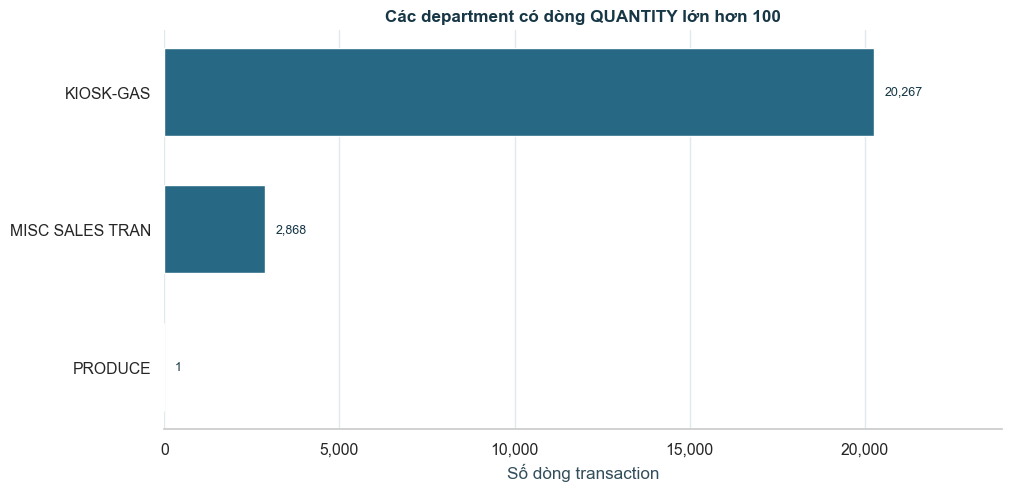

In [5]:
large_quantity = (tx.loc[tx.QUANTITY > 100]
    .groupby('DEPARTMENT', dropna=False)
    .agg(so_dong=('QUANTITY','size'), trung_vi=('QUANTITY','median'),
         lon_nhat=('QUANTITY','max'))
    .sort_values('so_dong', ascending=False))
display(large_quantity)
plot_quantity=large_quantity.head(8).sort_values('so_dong')
fig,ax=plt.subplots(figsize=(10,4.8),layout='constrained')
ax.barh(plot_quantity.index.astype(str),plot_quantity.so_dong,color=EDA_COLORS['blue'],height=.64)
ax.set(title='Các department có dòng QUANTITY lớn hơn 100',xlabel='Số dòng transaction',ylabel='')
ax.set_xlim(0,max(plot_quantity.so_dong.max()*1.18,1))
for y,value in enumerate(plot_quantity.so_dong):
    ax.text(value+plot_quantity.so_dong.max()*.015,y,f'{int(value):,}',va='center',fontsize=9,color=EDA_COLORS['dark'])
ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:,.0f}'))
ax.grid(axis='y',visible=False);sns.despine(ax=ax,left=True)
plt.show()


**Kết quả:** Có 23.136 dòng `QUANTITY > 100`; 20.267 dòng thuộc `KIOSK-GAS` và 2.868 dòng thuộc `MISC SALES TRAN`. User guide chưa xác nhận đơn vị hoặc hệ số quy đổi riêng cho các nhóm này, nên chưa thể kết luận giá trị lớn là lỗi.

**Quyết định đã thống nhất:** Giữ `QUANTITY` trong dữ liệu gốc, nhưng không tổng hợp xuyên department. Ta sử dụng basket và số ngày có basket để mô tả nhịp mua. Bước kế tiếp vì vậy là chuyển từ dòng sản phẩm sang basket.

## 3. Một household đã tạo ra bao nhiêu lần mua được ghi nhận?

Sau khi xác nhận basket ID nhất quán theo household và ngày, ta gom các dòng sản phẩm thành một dòng cho mỗi `(household_key, BASKET_ID, DAY)`. Điều này tránh đếm một giỏ gồm nhiều sản phẩm thành nhiều lần mua. Theo user guide, `SALES_VALUE` là số tiền retailer nhận được; khi có manufacturer coupon, số này có thể khác số tiền khách thực trả.

In [6]:
tx['is_grocery'] = tx.DEPARTMENT.eq('GROCERY')
tx['is_fuel'] = tx.DEPARTMENT.eq('KIOSK-GAS')
tx['coupon_line'] = tx.COUPON_DISC.lt(0) | tx.COUPON_MATCH_DISC.lt(0)
basket = (tx.groupby(['household_key','BASKET_ID','DAY'], observed=True)
    .agg(sales=('SALES_VALUE','sum'), so_dong=('PRODUCT_ID','size'),
         grocery=('is_grocery','max'), fuel=('is_fuel','max'),
         chi_co_fuel=('is_fuel','min'), coupon_discount=('coupon_line','max'))
    .reset_index())
basket['positive_sales'] = basket.sales.gt(0)
print('Số basket:', len(basket))
print('Basket tổng SALES_VALUE bằng 0:', int(basket.sales.eq(0).sum()))
print('Basket chỉ có KIOSK-GAS:', int(basket.chi_co_fuel.sum()))
display(basket.head())

Số basket: 276484
Basket tổng SALES_VALUE bằng 0: 942
Basket chỉ có KIOSK-GAS: 21108


,household_key,BASKET_ID,DAY,sales,so_dong,grocery,fuel,chi_co_fuel,coupon_discount,positive_sales
0,1,27601281299,51,78.66,30,True,False,False,True,True
1,1,27774192959,67,41.10,12,True,False,False,False,True
2,1,28024266849,88,26.90,12,True,False,False,False,True
3,1,28106322445,94,63.43,23,True,False,False,True,True
4,1,28235481967,101,53.45,17,True,False,False,False,True


## 4. Lịch sử có được quan sát đồng đều theo thời gian?

Một khoảng không có basket có thể phản ánh hành vi của hộ, nhưng cũng có thể nằm trước lúc hộ xuất hiện trong dữ liệu hoặc trùng một ngày toàn bộ nguồn có ít giao dịch. Ta xem số basket theo ngày và ngày xuất hiện đầu tiên của từng hộ. Cell này dùng toàn bộ dữ liệu nguồn để kiểm tra coverage, không dùng kết quả mô hình.

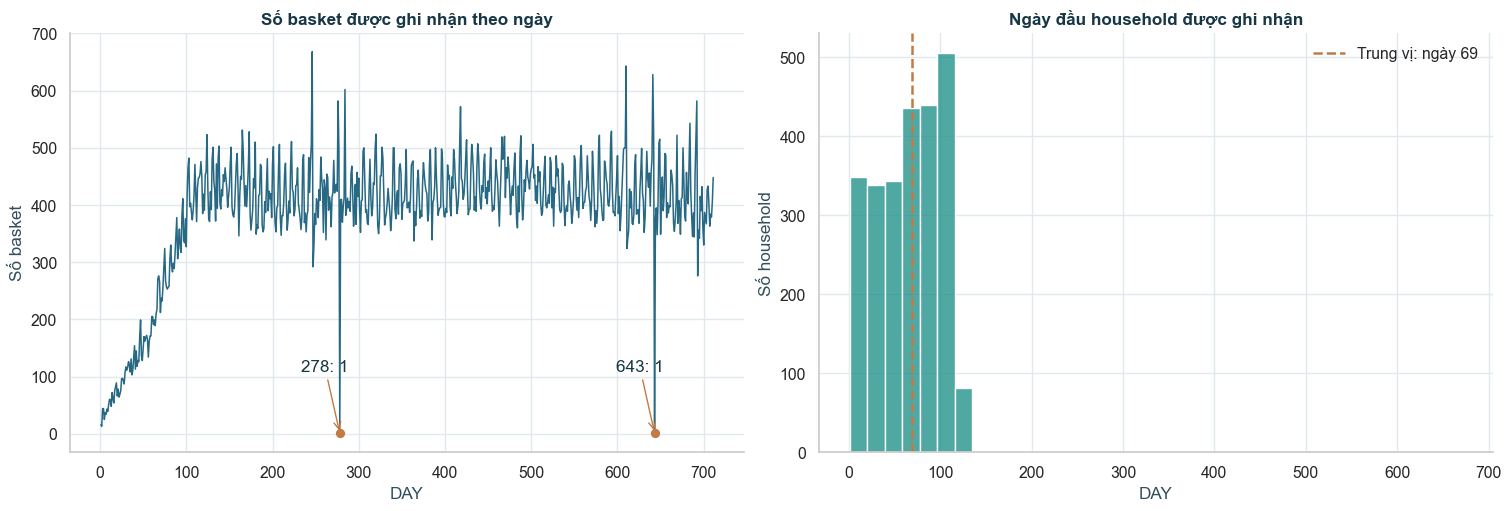

,so_basket,so_ho
DAY,,
278,1,1
643,1,1


,ngày đầu quan sát
count,2500.000000
mean,65.941200
std,39.152355
min,1.000000
25%,36.000000
50%,69.000000
75%,95.000000
max,671.000000


In [7]:
daily = basket.groupby('DAY').agg(so_basket=('BASKET_ID','size'), so_ho=('household_key','nunique'))
first_day = tx.groupby('household_key').DAY.min()
fig,axes=plt.subplots(1,2,figsize=(15,5),layout='constrained')
axes[0].plot(daily.index,daily.so_basket,color=EDA_COLORS['blue'],linewidth=1.1)
axes[0].set(title='Số basket được ghi nhận theo ngày',xlabel='DAY',ylabel='Số basket')
for day in (278,643):
    if day in daily.index:
        axes[0].scatter(day,daily.loc[day,'so_basket'],color=EDA_COLORS['orange'],s=32,zorder=4)
        axes[0].annotate(f'{day}: {daily.loc[day,"so_basket"]}',xy=(day,daily.loc[day,'so_basket']),
                         xytext=(day-45,110),color=EDA_COLORS['dark'],
                         arrowprops={'arrowstyle':'->','color':EDA_COLORS['orange']})
sns.histplot(x=first_day,bins=35,ax=axes[1],color=EDA_COLORS['teal'],edgecolor=None)
axes[1].axvline(first_day.median(),color=EDA_COLORS['orange'],linestyle='--',linewidth=1.8,
                label=f'Trung vị: ngày {first_day.median():.0f}')
axes[1].set(title='Ngày đầu household được ghi nhận',xlabel='DAY',ylabel='Số household')
axes[1].legend(frameon=False);sns.despine(fig=fig);plt.show()
display(daily.loc[daily.index.intersection([278, 643])])
display(first_day.describe().rename('ngày đầu quan sát').to_frame())

**Kết quả:** Household xuất hiện dần trong panel; trung vị ngày xuất hiện đầu tiên là ngày 69. Ngày 278 và 643 mỗi ngày chỉ có một basket, khác biệt rõ so với phần lớn chuỗi, nhưng nguyên nhân chưa được xác nhận.

**Hàm ý:** Không coi khoảng trước lần đầu quan sát là lịch sử không mua. Khi tạo snapshot, chỉ xét những hộ đã xuất hiện đến cutoff; tác động tiềm tàng của hai ngày bất thường sẽ được lượng hóa ở phần cuối notebook. Sau đây ta cần định nghĩa chính xác sự kiện muốn dự báo.

## 5. Xây dựng household-snapshot và target đã chọn

Tại cutoff `s`, household đủ điều kiện nếu có ít nhất một basket đã quan sát tới `s`. **Target đã được bạn xác nhận:** `target_any_basket = 1` nếu có bất kỳ `BASKET_ID` nào trong `(s, s+7]`; ngược lại bằng 0. Nhãn bao gồm fuel, miscellaneous và basket có tổng `SALES_VALUE = 0`; không áp dụng bộ lọc department hoặc giá trị.

1. `any_basket`: ít nhất một basket bất kỳ — **target được chọn**.
2. `positive_basket`: ít nhất một basket có tổng `SALES_VALUE > 0`.
3. `grocery_department`: ít nhất một basket có dòng `DEPARTMENT = GROCERY`. Nhóm này **không bao gồm mọi loại thực phẩm**, ví dụ `PRODUCE` hay `MEAT`.

Hai định nghĩa sau chỉ dùng để phân tích độ nhạy; không thay thế target đã chọn.

In [8]:
SNAPSHOTS = range(180, 538, 7)
HORIZON = 7
MAX_DAY = int(basket.DAY.max())
assert max(SNAPSHOTS) + HORIZON <= MAX_DAY
by_day = (basket.groupby(['household_key','DAY'], observed=True)
    .agg(any_basket=('BASKET_ID','size'), positive_basket=('positive_sales','sum'),
         grocery_department=('grocery','sum'), fuel_basket=('fuel','sum'),
         coupon_basket=('coupon_discount','sum')).reset_index())
households = np.sort(by_day.household_key.unique())
matrices = {}
for name in ['any_basket','positive_basket','grocery_department','fuel_basket','coupon_basket']:
    matrices[name] = (by_day.pivot(index='household_key', columns='DAY', values=name)
        .reindex(index=households, columns=range(MAX_DAY + 1)).fillna(0).to_numpy(dtype=np.int32))
cumulative = {name: np.cumsum(values, axis=1, dtype=np.int64) for name, values in matrices.items()}
active = matrices['any_basket'] > 0
day_axis = np.arange(MAX_DAY + 1)[None, :]
first = np.where(active, day_axis, MAX_DAY + 1).min(axis=1)
last = np.maximum.accumulate(np.where(active, day_axis, -1), axis=1)
active_cumulative = np.cumsum(active, axis=1)
frames = []
for s in SNAPSHOTS:
    data = {'household_key': households, 'snapshot_day': s, 'recency_days': s - last[:, s],
            'active_days_90d': active_cumulative[:, s] - active_cumulative[:, s-90]}
    for name in ['fuel_basket','coupon_basket']:
        data[name + '_90d'] = cumulative[name][:, s] - cumulative[name][:, s-90]
    for name in ['any_basket','positive_basket','grocery_department']:
        data['target_' + name] = (cumulative[name][:, s+HORIZON] - cumulative[name][:, s] > 0).astype(int)
    frames.append(pd.DataFrame(data).loc[first <= s])
panel = pd.concat(frames, ignore_index=True)
assert not panel.duplicated(['household_key','snapshot_day']).any()
assert (panel.target_positive_basket <= panel.target_any_basket).all()
assert (panel.target_grocery_department <= panel.target_any_basket).all()
print('Snapshot:', panel.snapshot_day.nunique(), '| Household-snapshot:', len(panel), '| Hộ:', panel.household_key.nunique())

Snapshot: 52 | Household-snapshot: 129834 | Hộ: 2498


### 5.1. Kiểm tra nhãn từ basket thô

Trước khi diễn giải tỷ lệ mua, ta đối chiếu 100 household-snapshot với các basket nguồn theo đúng khoảng `(s, s+7]`. Đây là kiểm tra mẫu; các assertion ở cell trước kiểm tra những quan hệ tập hợp trên toàn panel.

In [9]:
for row in panel.sample(min(100, len(panel)), random_state=42).itertuples(index=False):
    future = basket[(basket.household_key == row.household_key) &
                    (basket.DAY > row.snapshot_day) & (basket.DAY <= row.snapshot_day + HORIZON)]
    assert int(not future.empty) == row.target_any_basket
    assert int(future.positive_sales.any()) == row.target_positive_basket
    assert int(future.grocery.any()) == row.target_grocery_department
print('Kiểm tra 100 household-snapshot: PASS')

Kiểm tra 100 household-snapshot: PASS


### 5.2. Cùng dữ liệu, định nghĩa mua hàng làm thay đổi kết quả như thế nào?

Ta so sánh target đã chọn với hai định nghĩa thay thế để hiểu hệ quả của quyết định nghiệp vụ. Đơn vị đếm là household-snapshot: cùng một hộ có thể xuất hiện ở nhiều cutoff, nên số dòng không phải số hộ độc lập.

,định nghĩa,số household-snapshot,số nhãn dương,tỷ lệ dương,số nhãn khác any_basket
0,any_basket,129834,68544,0.527936,0
1,positive_basket,129834,68511,0.527682,33
2,grocery_department,129834,63235,0.487045,5309


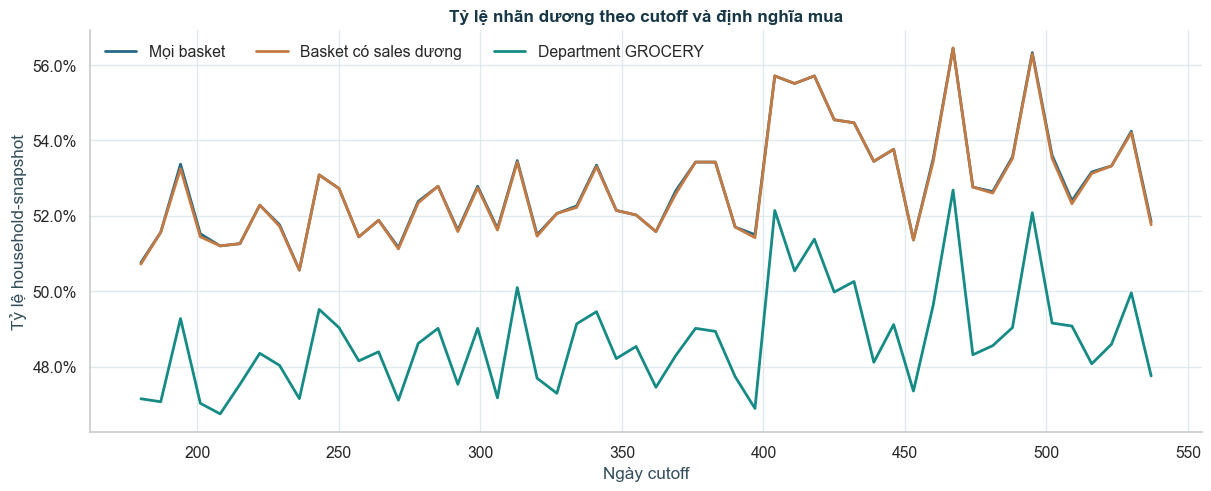

In [10]:
target_columns = ['target_any_basket','target_positive_basket','target_grocery_department']
scenario_summary = pd.DataFrame([{
    'định nghĩa': col.replace('target_',''), 'số household-snapshot': len(panel),
    'số nhãn dương': int(panel[col].sum()), 'tỷ lệ dương': panel[col].mean(),
    'số nhãn khác any_basket': int(panel[col].ne(panel.target_any_basket).sum())
} for col in target_columns])
display(scenario_summary)
weekly_rates = panel.groupby('snapshot_day')[target_columns].mean()
fig,ax=plt.subplots(figsize=(12,4.8),layout='constrained')
for column,label,color in [('target_any_basket','Mọi basket',EDA_COLORS['blue']),
                           ('target_positive_basket','Basket có sales dương',EDA_COLORS['orange']),
                           ('target_grocery_department','Department GROCERY',EDA_COLORS['teal'])]:
    ax.plot(weekly_rates.index,weekly_rates[column],label=label,color=color,linewidth=2)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(title='Tỷ lệ nhãn dương theo cutoff và định nghĩa mua',xlabel='Ngày cutoff',ylabel='Tỷ lệ household-snapshot')
ax.legend(frameon=False,ncol=3,loc='best');sns.despine(ax=ax);plt.show()


**Kết quả:** Trong các household-snapshot được khảo sát, 52,79% có ít nhất một basket trong 7 ngày kế tiếp. So với target này, yêu cầu basket có tổng sales dương làm thay đổi 33 nhãn; chỉ xét department `GROCERY` làm thay đổi 5.309 nhãn.

**Ý nghĩa:** Phạm vi hàng hóa ảnh hưởng đến câu hỏi nghiên cứu. Ta tiếp tục với mọi basket như đã thống nhất; hai phương án còn lại giúp hiểu độ nhạy, không đại diện cho định nghĩa chính. Khi đã có nhãn rõ ràng, ta xem lịch sử mua liên hệ với kết quả tương lai ra sao.

## 6. Lịch sử mua có liên hệ với việc quay lại trong 7 ngày?

Trước hết, ta quan sát hai góc nhìn bổ sung: `recency` là số ngày từ basket gần nhất đến cutoff, còn `active_days_90d` là số ngày có basket trong `(s-90, s]`. Tỷ lệ bên dưới là tỷ lệ quan sát được trong từng nhóm, không chứng minh quan hệ nguyên nhân–kết quả.

,recency_group,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0-7,73142,2464,51546,0.704739
1,8-14,16994,2333,8334,0.490408
2,15-30,15233,2031,5359,0.351802
3,31-60,9698,1456,2021,0.208393
4,61-90,4511,921,611,0.135447
5,91+,10256,661,673,0.065620


,activity_group,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,10357,670,688,0.066429
1,1-3,22108,1296,4551,0.205853
2,4-9,35000,1762,14383,0.410943
3,10-18,32514,1622,22091,0.679430
4,19+,29855,1085,26831,0.898710


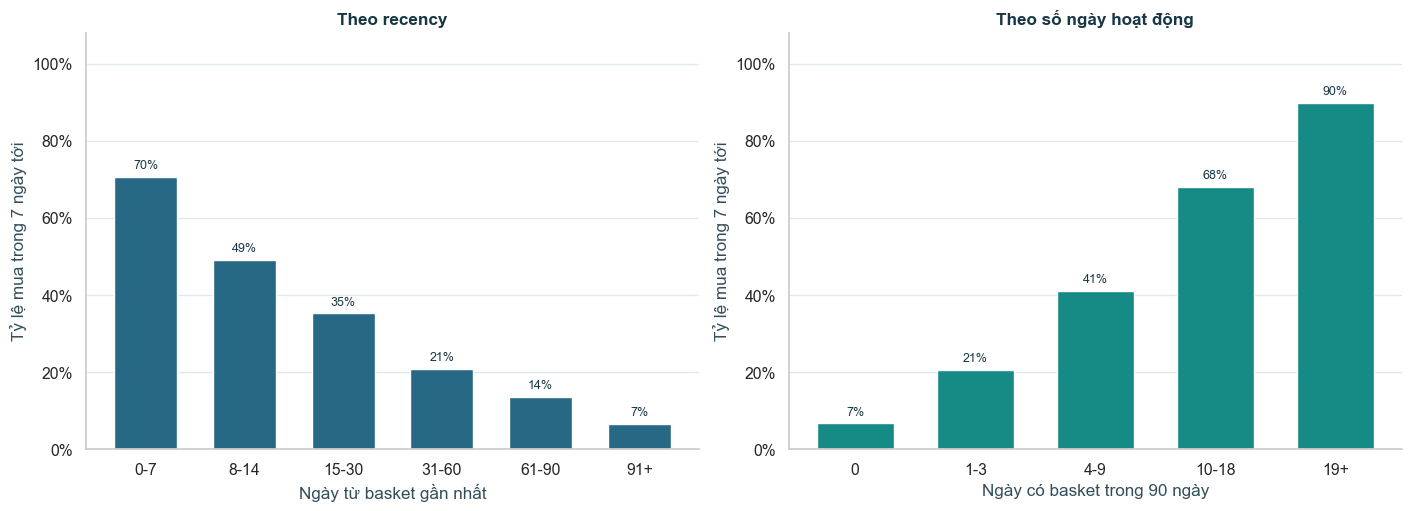

In [11]:
panel['recency_group'] = pd.cut(panel.recency_days, [-1,7,14,30,60,90,np.inf], labels=['0-7','8-14','15-30','31-60','61-90','91+'])
panel['activity_group'] = pd.cut(panel.active_days_90d, [-1,0,3,9,18,np.inf], labels=['0','1-3','4-9','10-18','19+'])
def group_summary(frame, columns):
    return (frame.groupby(columns, observed=True, dropna=False)
        .agg(household_snapshots=('household_key','size'), unique_households=('household_key','nunique'),
             positive_snapshots=('target_any_basket','sum'), purchase_rate=('target_any_basket','mean'))
        .reset_index())
recency_summary = group_summary(panel, ['recency_group'])
activity_summary = group_summary(panel, ['activity_group'])
display(recency_summary)
display(activity_summary)
fig,axes=plt.subplots(1,2,figsize=(14,5),layout='constrained')
for ax,table,xcol,title,xlabel,color in [
    (axes[0],recency_summary,'recency_group','Theo recency','Ngày từ basket gần nhất',EDA_COLORS['blue']),
    (axes[1],activity_summary,'activity_group','Theo số ngày hoạt động','Ngày có basket trong 90 ngày',EDA_COLORS['teal'])]:
    values=table.purchase_rate.to_numpy();bars=ax.bar(table[xcol].astype(str),values,color=color,width=.64)
    ax.bar_label(bars,labels=[f'{v:.0%}' for v in values],padding=4,fontsize=9,color=EDA_COLORS['dark'])
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.set(title=title,xlabel=xlabel,ylabel='Tỷ lệ mua trong 7 ngày tới',ylim=(0,1.08))
    ax.grid(axis='x',visible=False);sns.despine(ax=ax)
plt.show()


**Kết quả:** Nhóm mua gần nhất trong 0–7 ngày có tỷ lệ phát sinh basket trong 7 ngày tiếp theo khoảng 70,47%; ở nhóm recency từ 91 ngày trở lên, tỷ lệ khoảng 6,56%. Phân nhóm theo số ngày hoạt động cũng cho thấy nhịp mua gắn với khả năng quay lại.

**Ý nghĩa:** Thời điểm và tần suất giao dịch là những hướng phân tích có triển vọng. Tuy nhiên, cùng một hộ xuất hiện nhiều tuần nên các household-snapshot không độc lập. Để hình dung sự đa dạng đằng sau các tỷ lệ tổng hợp, ta xem lịch sử của một số household cụ thể.

### 6.1. Lịch mua của 40 household theo mức độ hoạt động

Để minh họa các nhịp mua khác nhau, ta chọn có chủ đích 4 nhóm, mỗi nhóm 10 household: **min**, **gần mean**, **gần median** và **max** của số ngày có basket trong `(537-90, 537]`. Mean và median được tính trên toàn bộ household đủ điều kiện tại cutoff ngày 537; không tính bằng số basket.

Chọn theo thứ tự min → mean → median → max, mỗi bước loại các household đã chọn; trong nhóm mean/median xếp theo khoảng cách tuyệt đối đến giá trị tương ứng. Đồng hạng được phá bằng `household_key` tăng dần. Vì loại trùng giữa nhóm, một hộ đủ điều kiện ở nhiều nhóm chỉ xuất hiện ở nhóm được chọn trước; các nhóm sau lấy hộ gần tiêu chí nhất trong số còn lại. Đây là mẫu minh họa có chủ đích, không đại diện thống kê cho toàn bộ household.

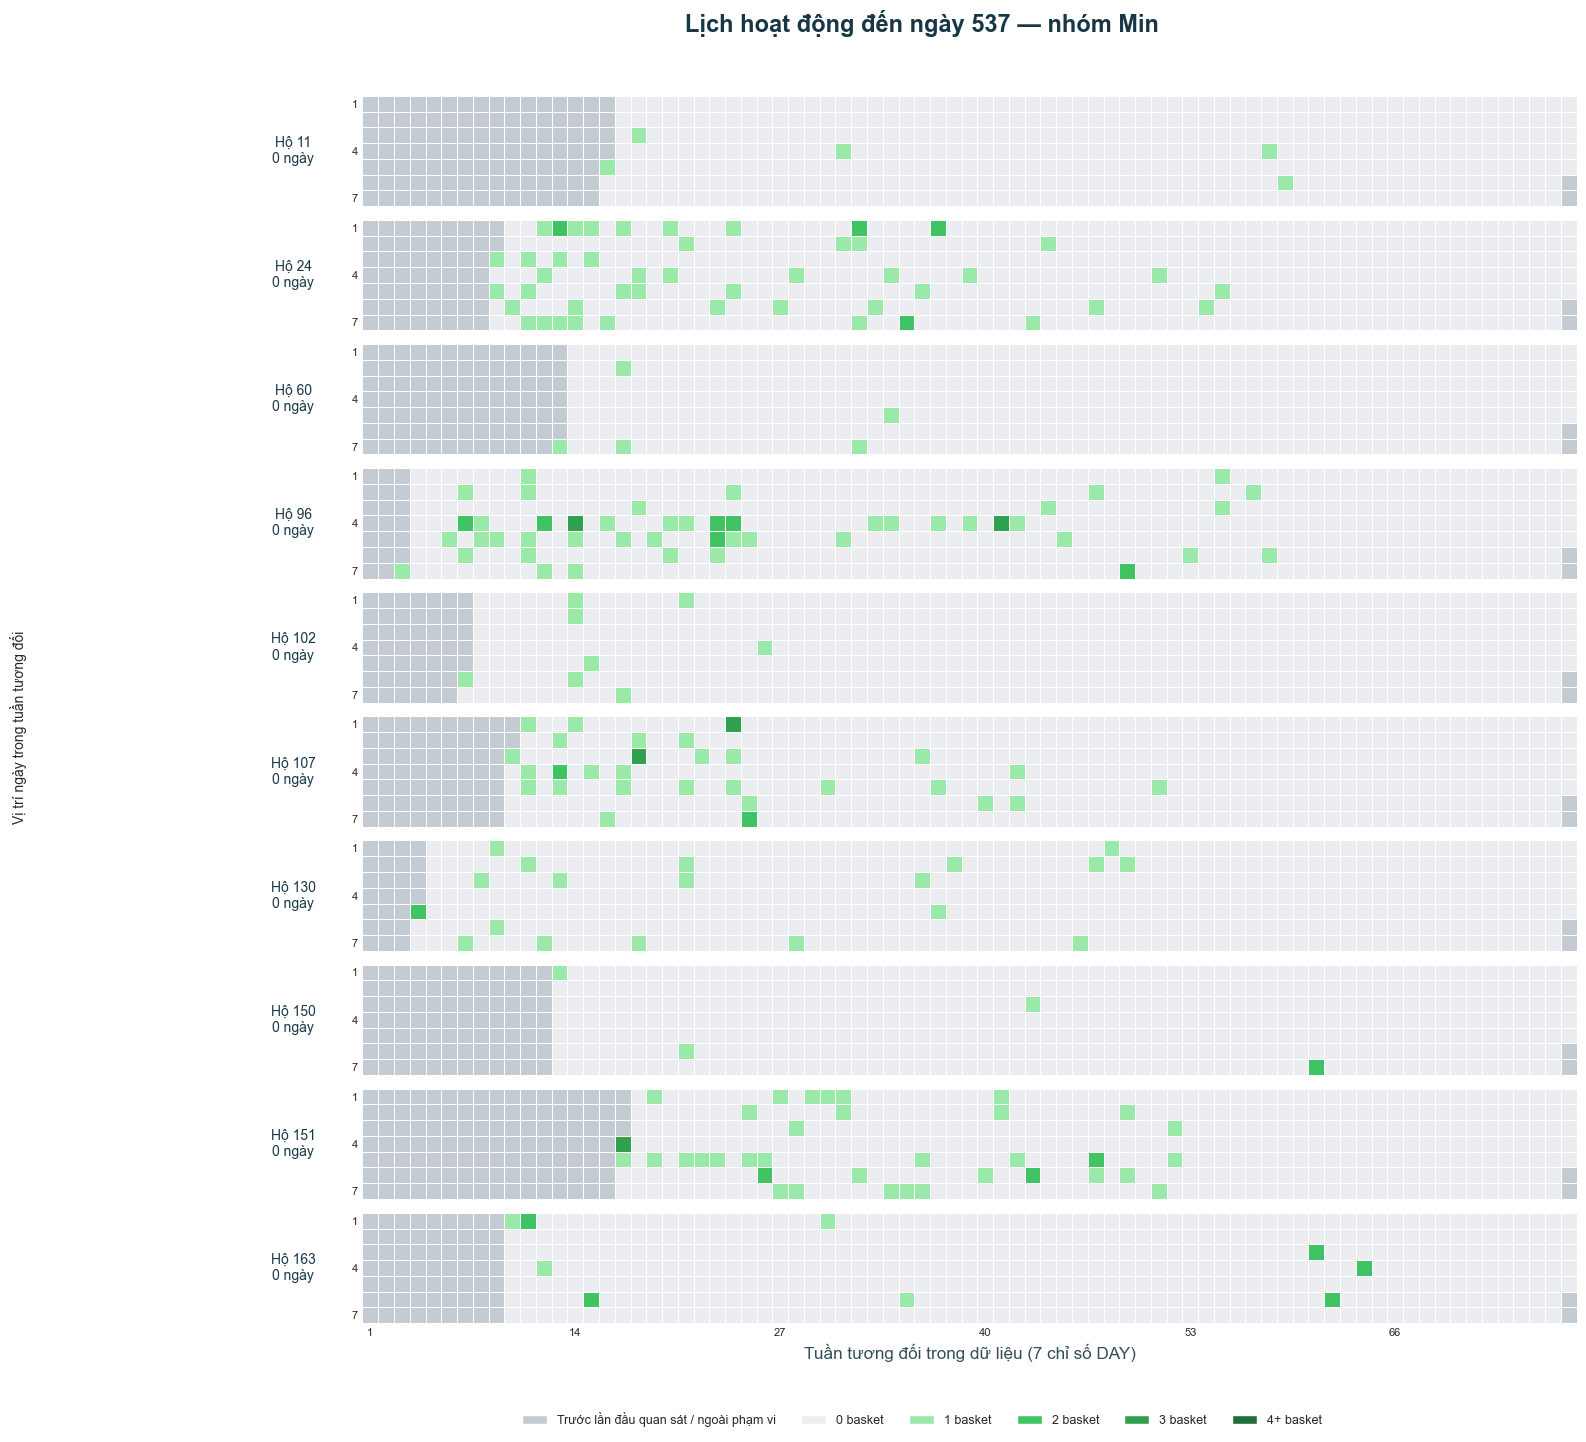

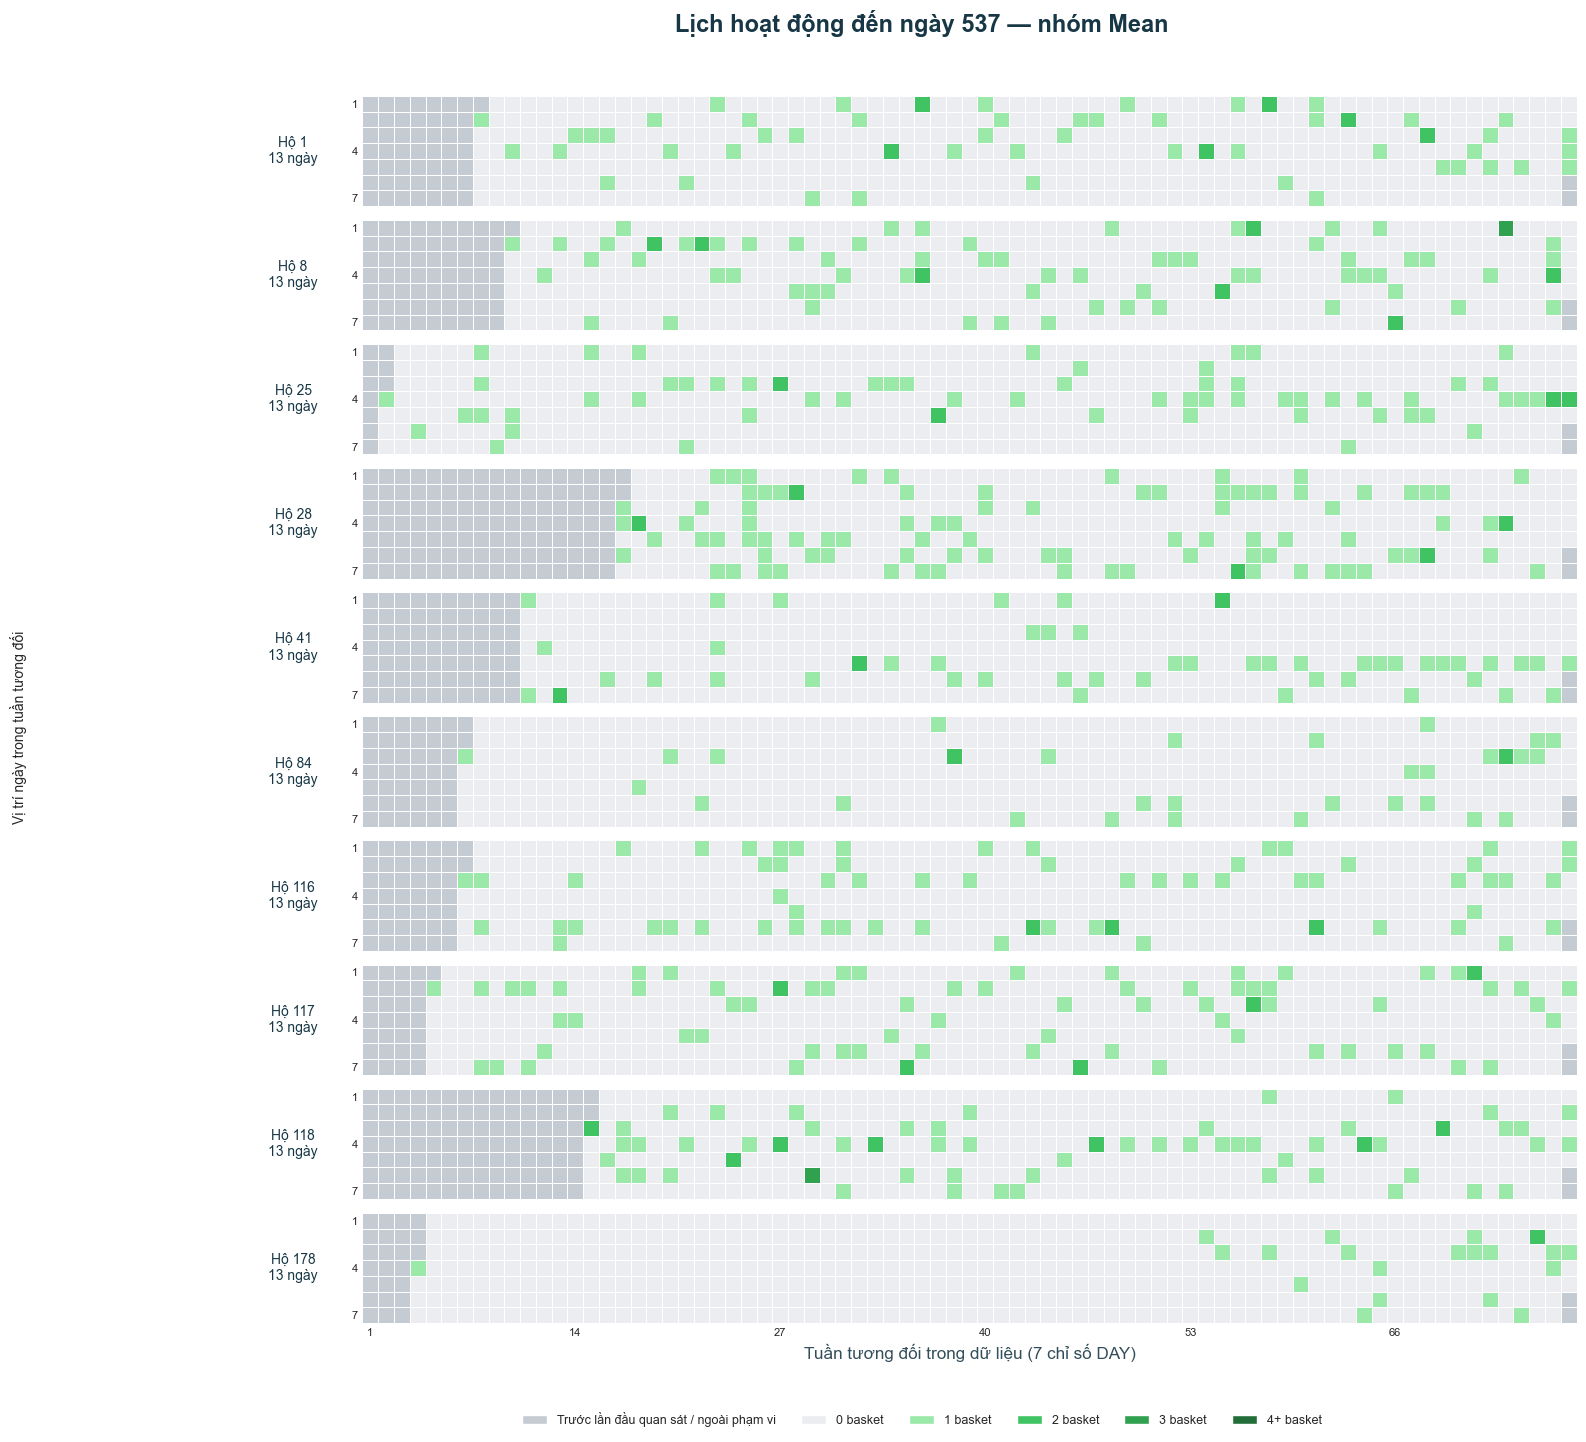

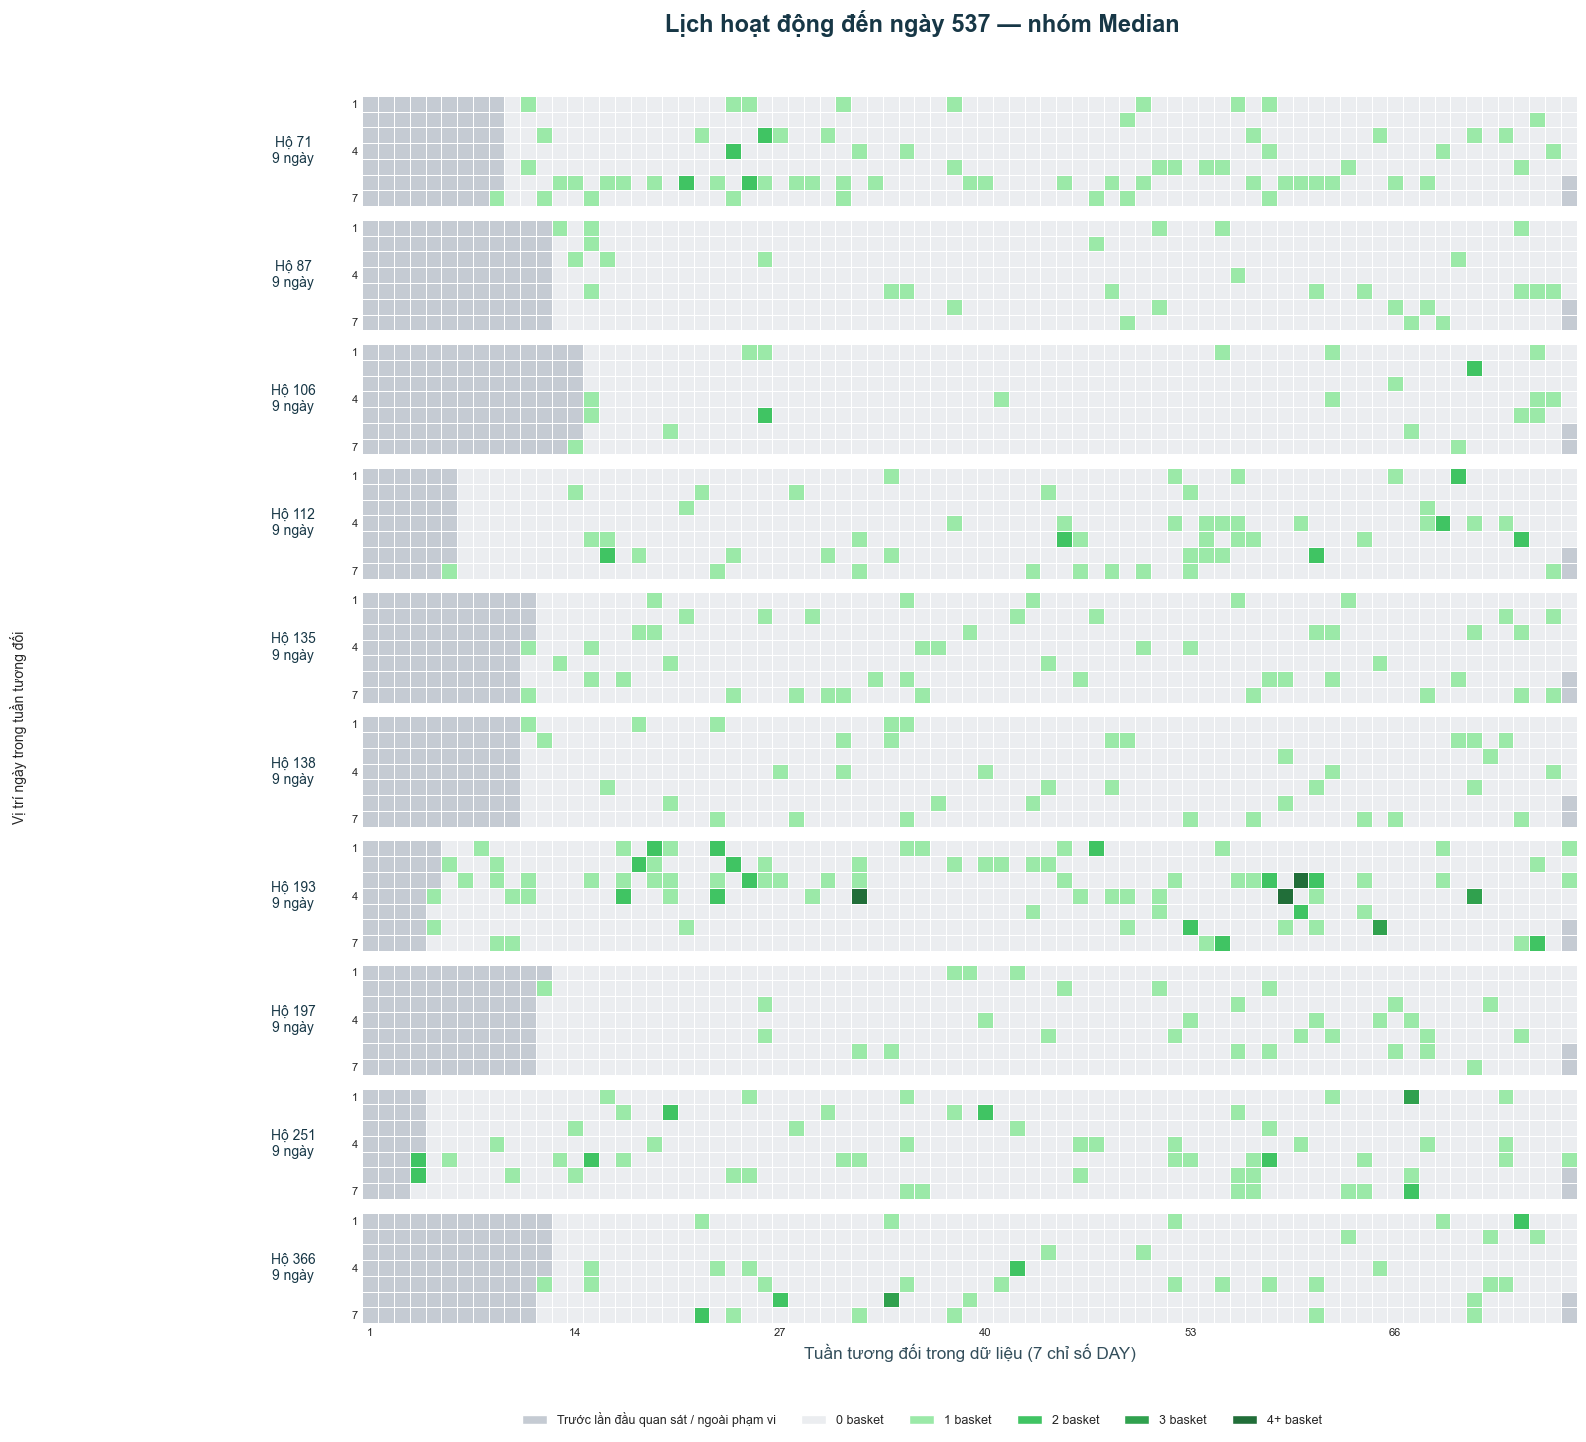

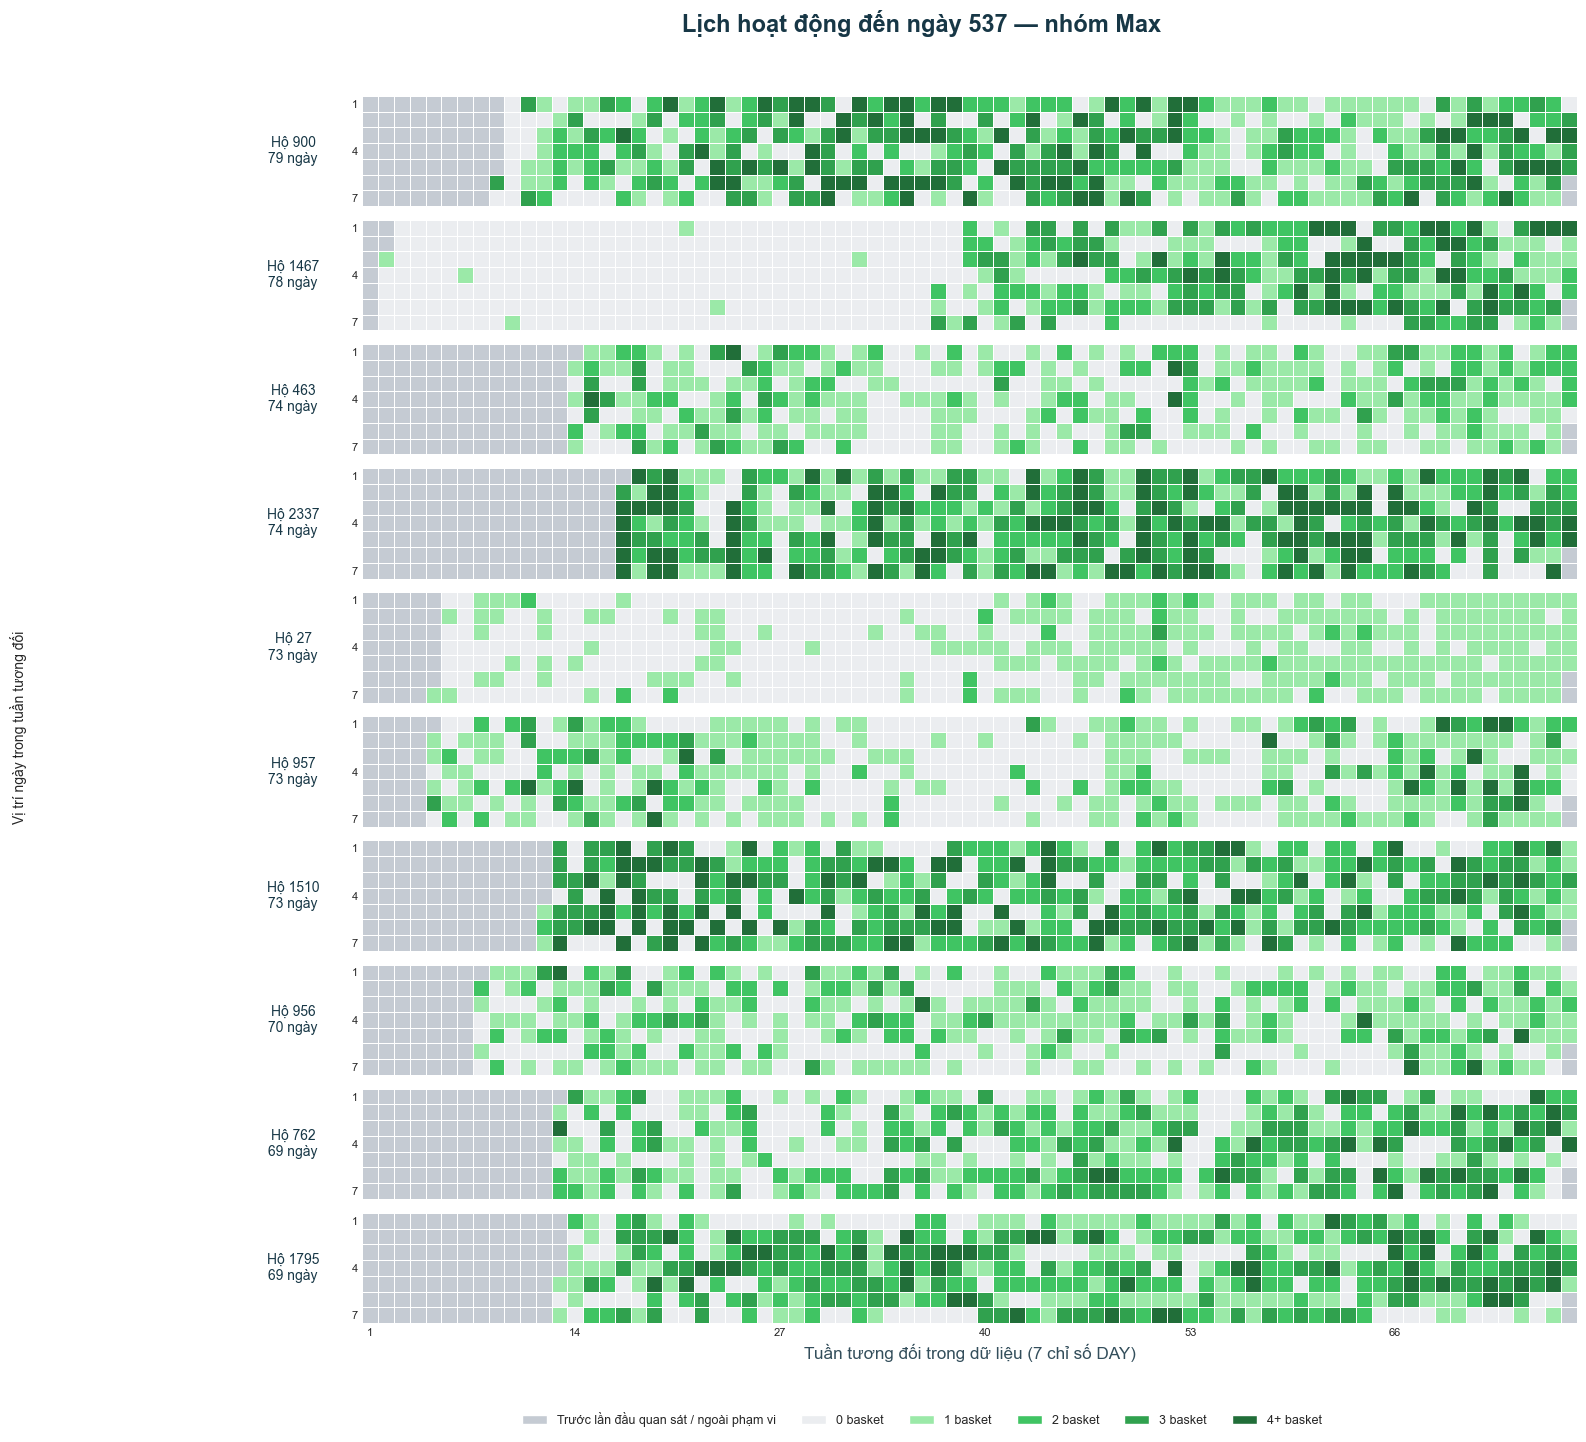

In [12]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

calendar_cutoff = 537
selection_base = panel.loc[panel.snapshot_day.eq(calendar_cutoff),
                           ['household_key', 'active_days_90d']].copy()
assert len(selection_base) >= 40 and selection_base.household_key.is_unique
activity_mean = selection_base.active_days_90d.mean()
activity_median = selection_base.active_days_90d.median()
chosen = set()
selected_groups = []
for group, criterion in [('Min', 'min'), ('Mean', activity_mean),
                         ('Median', activity_median), ('Max', 'max')]:
    candidates = selection_base.loc[~selection_base.household_key.isin(chosen)].copy()
    if criterion == 'min':
        candidates['distance'] = candidates.active_days_90d
    elif criterion == 'max':
        candidates['distance'] = -candidates.active_days_90d
    else:
        candidates['distance'] = (candidates.active_days_90d - criterion).abs()
    selected = candidates.sort_values(['distance', 'household_key']).head(10).copy()
    selected['nhóm'] = group
    selected_groups.append(selected)
    chosen.update(selected.household_key)
selection = pd.concat(selected_groups, ignore_index=True)
assert len(selection) == 40 and selection.household_key.nunique() == 40
assert selection.groupby('nhóm').size().eq(10).all()
calendar_baskets = basket.loc[(basket.DAY <= calendar_cutoff) &
                              basket.household_key.isin(selection.household_key)]
daily_counts = calendar_baskets.groupby(['household_key', 'DAY']).BASKET_ID.nunique()
number_of_weeks = (calendar_cutoff + 6) // 7
colors = ['#ebedf0', '#9be9a8', '#40c463', '#30a14e', '#216e39']
cmap = ListedColormap(colors)
cmap.set_bad('#c5cbd3')
norm = BoundaryNorm(np.arange(-0.5, 5.5, 1), cmap.N)
for group in ['Min', 'Mean', 'Median', 'Max']:
    group_rows = selection.loc[selection['nhóm'].eq(group)]
    fig, axes = plt.subplots(10, 1, figsize=(19, 14.5), sharex=True, squeeze=False)
    for ax, row in zip(axes[:, 0], group_rows.itertuples(index=False)):
        household = row.household_key
        counts = daily_counts.loc[household]
        first_observed_day = int(counts.index.min())
        grid = np.full((7, number_of_weeks), np.nan)
        for day in range(first_observed_day, calendar_cutoff + 1):
            grid[(day - 1) % 7, (day - 1) // 7] = min(int(counts.get(day, 0)), 4)
        ax.pcolormesh(np.arange(number_of_weeks + 1), np.arange(8),
                      np.ma.masked_invalid(grid), cmap=cmap, norm=norm,
                      edgecolors='white', linewidth=0.45, shading='flat')
        ax.set_ylim(7, 0)
        ax.set_aspect('equal')
        ax.set_yticks([0.5, 3.5, 6.5], ['1', '4', '7'])
        ax.tick_params(axis='both', length=0, labelsize=8)
        ax.set_ylabel(f'Hộ {household}\n{row.active_days_90d} ngày', rotation=0,
                      labelpad=42, va='center', fontsize=10, color=EDA_COLORS['dark'])
        for spine in ax.spines.values():
            spine.set_visible(False)
    tick_positions = np.arange(0, number_of_weeks, 13)
    axes[-1, 0].set_xticks(tick_positions + .5, tick_positions + 1)
    axes[-1, 0].set_xlabel('Tuần tương đối trong dữ liệu (7 chỉ số DAY)')
    legend = [Patch(facecolor='#c5cbd3', label='Trước lần đầu quan sát / ngoài phạm vi'),
              *[Patch(facecolor=color, label=label) for color, label in
                zip(colors, ['0 basket', '1 basket', '2 basket', '3 basket', '4+ basket'])]]
    fig.legend(handles=legend, loc='lower center', ncol=6, frameon=False, fontsize=9,
               bbox_to_anchor=(.5, .01))
    fig.suptitle(f'Lịch hoạt động đến ngày {calendar_cutoff} — nhóm {group}', fontsize=17, fontweight='bold', color=EDA_COLORS['dark'], y=.995)
    fig.text(.02, .5, 'Vị trí ngày trong tuần tương đối', rotation=90, va='center', fontsize=10)
    fig.tight_layout(rect=[.05, .05, 1, .98], h_pad=.8)
    plt.show()

**Cách đọc:** Mỗi cột là một tuần tương đối; bảy hàng là các vị trí `DAY` trong tuần, chưa thể gán thứ Hai–Chủ nhật. Màu xanh biểu thị số basket mỗi ngày; số bên cạnh household là số ngày hoạt động trong 90 ngày dùng để chọn nhóm. Màu xám đánh dấu thời gian trước lần đầu household được ghi nhận hoặc ngoài phạm vi đến cutoff; ô không có basket chỉ thể hiện không có giao dịch được ghi nhận.

Các nhóm cho thấy các trường hợp từ ít đến nhiều hoạt động, nhưng min và max là cực trị; mean và median chỉ là các hộ gần giá trị tương ứng. Không suy rộng tỷ lệ nhóm mẫu cho toàn bộ household. Ta tiếp tục tìm hiểu thành phần giỏ hàng của toàn bộ panel.

## 6.2. Household mua những nhóm hàng nào?

Sau khi quan sát nhịp mua, ta xem nội dung giỏ hàng: số department khác nhau trong `(s-90, s]` có liên hệ thế nào với việc mua tiếp? Phân tích dùng các snapshot train đã xây dựng, không cộng `QUANTITY` và không gán nhãn sở thích cho household. Mỗi dòng household–basket–department chỉ được tính một lần.

Theo gợi ý về sự khác biệt hành vi trong [Liu & Chen (2026)](https://www.sciencedirect.com/science/article/pii/S0969698925004242), ta khảo sát phân bố và phân tầng theo số ngày hoạt động. Đây là cách vận dụng cho bài toán hiện tại, không tái lập phương pháp phân nhóm của bài báo.

notebook-cell/1470894386.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  basket_history['has_discount'] = basket_history.has_discount.fillna(False).astype(bool)


,dept_group,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,10357,670,688,0.066429
1,1–3,14867,1144,3438,0.231250
2,4–6,30683,1762,12442,0.405501
3,7–10,49994,2036,31693,0.633936
4,11+,23933,1060,20283,0.847491


,activity_group,dept_group,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,0,10357,670,688,0.066429
1,1-3,1–3,11188,1004,2040,0.182338
2,1-3,4–6,8679,1010,1966,0.226524
3,1-3,7–10,2228,393,544,0.244165
4,1-3,11+,13,5,1,0.076923
5,4-9,1–3,3122,484,1040,0.333120
6,4-9,4–6,15101,1349,5774,0.382359
7,4-9,7–10,15462,1314,6891,0.445673
8,4-9,11+,1315,230,678,0.515589
9,10-18,1–3,499,87,312,0.625251


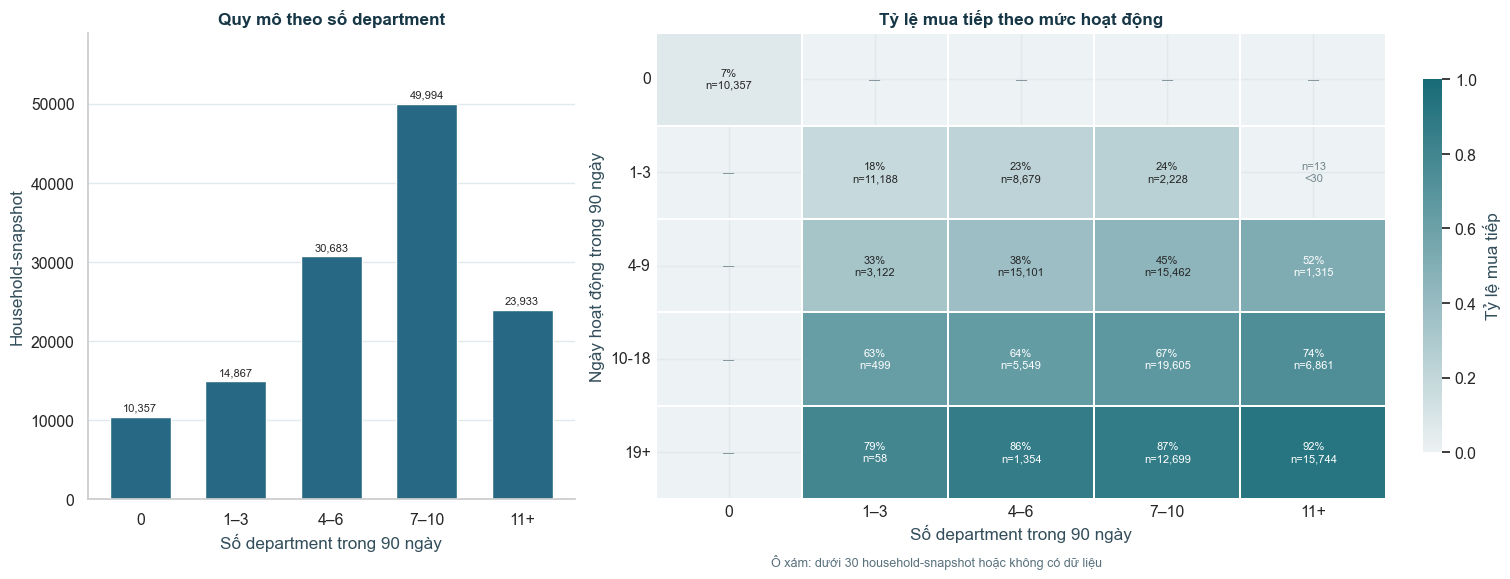

In [13]:
# Tính độc lập tại từng cutoff; mọi giao dịch đều nằm trước hoặc tại cutoff.
dept_tx = tx[['household_key', 'BASKET_ID', 'DAY', 'DEPARTMENT']].drop_duplicates()
basket_history = basket[['household_key', 'DAY', 'BASKET_ID', 'coupon_discount']].copy()
tx_discount = (tx.RETAIL_DISC.lt(0) | tx.COUPON_DISC.lt(0) | tx.COUPON_MATCH_DISC.lt(0))
discount_baskets = (tx.loc[tx_discount, ['household_key', 'DAY', 'BASKET_ID']]
                    .drop_duplicates().assign(has_discount=True))
basket_history = basket_history.merge(discount_baskets, on=['household_key', 'DAY', 'BASKET_ID'],
                                      how='left', validate='one_to_one')
basket_history['has_discount'] = basket_history.has_discount.fillna(False).astype(bool)
history_frames = []
for s in SNAPSHOTS:
    window_dept = dept_tx.loc[dept_tx.DAY.between(s-89, s)]
    d = window_dept.groupby('household_key').DEPARTMENT.nunique().rename('departments_90d')
    window_baskets = basket_history.loc[basket_history.DAY.between(s-89, s)]
    b = window_baskets.groupby('household_key').agg(
        baskets_90d=('BASKET_ID', 'size'), discount_baskets_90d=('has_discount', 'sum'))
    h = b.join(d, how='outer').fillna(0).reset_index()
    h['snapshot_day'] = s
    history_frames.append(h)
history90 = pd.concat(history_frames, ignore_index=True)
explore = panel.merge(history90, on=['household_key', 'snapshot_day'], how='left', validate='one_to_one')
for col in ['departments_90d', 'baskets_90d', 'discount_baskets_90d']:
    explore[col] = explore[col].fillna(0).astype(int)
assert (explore.discount_baskets_90d <= explore.baskets_90d).all()
assert (explore.active_days_90d <= explore.baskets_90d).all()
explore['dept_group'] = pd.cut(explore.departments_90d, [-1, 0, 3, 6, 10, np.inf],
                               labels=['0', '1–3', '4–6', '7–10', '11+'])
dept_summary = group_summary(explore, ['dept_group'])
dept_strata = group_summary(explore, ['activity_group', 'dept_group'])
display(dept_summary)
display(dept_strata)
fig,axes=plt.subplots(1,2,figsize=(15,5.5),gridspec_kw={'width_ratios':[.8,1.2]},layout='constrained')
bars=axes[0].bar(dept_summary.dept_group.astype(str),dept_summary.household_snapshots,
                 color=EDA_COLORS['blue'],width=.64)
axes[0].bar_label(bars,labels=[f'{int(v):,}' for v in dept_summary.household_snapshots],padding=3,fontsize=8)
axes[0].set(title='Quy mô theo số department',xlabel='Số department trong 90 ngày',ylabel='Household-snapshot')
axes[0].set_ylim(0,dept_summary.household_snapshots.max()*1.18);axes[0].grid(axis='x',visible=False);sns.despine(ax=axes[0])
eda_rate_heatmap(axes[1],dept_strata,'activity_group','dept_group','Tỷ lệ mua tiếp theo mức hoạt động',
                 'Số department trong 90 ngày','Ngày hoạt động trong 90 ngày')
fig.text(.51,-.02,'Ô xám: dưới 30 household-snapshot hoặc không có dữ liệu',fontsize=9,color=EDA_COLORS['muted'])
plt.show()


**Kết quả:** Nhóm có 1–3 department có tỷ lệ mua tiếp 23,13%; nhóm từ 11 department trở lên đạt 84,75% khi so sánh tổng thể. Trong cùng nhóm 4–9 ngày hoạt động, tỷ lệ theo các nhóm 1–3, 4–6, 7–10 và 11+ department lần lượt là 33,31%, 38,24%, 44,57% và 51,56%.

**Cách diễn giải:** Các nhóm là khoảng đếm department, không phải phân khúc khách hàng. So sánh trong cùng nhóm activity giúp xem xét một phần khác biệt về nhịp mua, nhưng không loại bỏ mọi yếu tố gây nhiễu. Đọc cùng số household riêng biệt và household-snapshot; các snapshot của một household không độc lập. Ô ít quan sát có thể biến động mạnh.

Sau sự đa dạng về hàng hóa, ta xem một đặc điểm khác của basket: sự hiện diện của discount.

## 6.3. Discount hiện diện trong lịch sử basket như thế nào?

Một basket được đánh dấu có discount nếu ít nhất một dòng có `RETAIL_DISC`, `COUPON_DISC` hoặc `COUPON_MATCH_DISC` âm. Tỷ lệ được tính bằng số basket có discount chia số basket trong `(s-90, s]`. Nhóm không có basket được tách riêng vì tỷ lệ không xác định; discount gắn với giao dịch không đo được việc tiếp xúc ưu đãi trước mua.

,discount_group,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0%,1661,273,278,0.167369
1,>0–25%,551,111,178,0.323049
2,>25–50%,5586,732,1918,0.343358
3,>50–75%,21061,1600,12154,0.577086
4,>75–100%,90618,2450,53328,0.588492
5,Không có basket,10357,670,688,0.066429


,activity_group,discount_group,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,Không có basket,10357,670,688,0.066429
1,1-3,0%,1600,272,270,0.168750
2,1-3,>0–25%,53,13,4,0.075472
3,1-3,>25–50%,2725,500,550,0.201835
4,1-3,>50–75%,2346,581,584,0.248934
5,1-3,>75–100%,15384,1178,3143,0.204303
6,4-9,0%,61,14,8,0.131148
7,4-9,>0–25%,433,95,135,0.311778
8,4-9,>25–50%,1852,378,647,0.349352
9,4-9,>50–75%,7149,1027,2781,0.389005


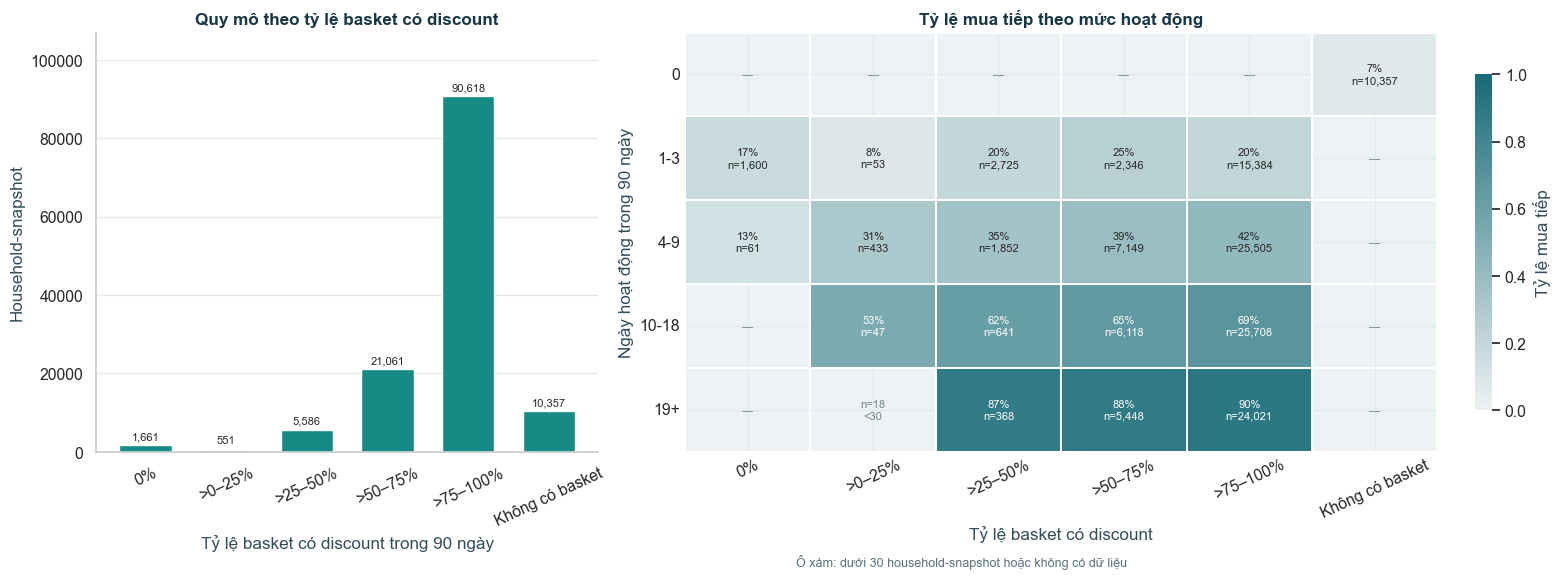

In [14]:
explore['discount_share'] = (explore.discount_baskets_90d /
                             explore.baskets_90d.replace(0, np.nan))
explore['discount_group'] = pd.cut(explore.discount_share, [-.001, 0, .25, .5, .75, 1],
                                    labels=['0%', '>0–25%', '>25–50%', '>50–75%', '>75–100%'])
explore['discount_group'] = explore.discount_group.cat.add_categories(['Không có basket']).fillna('Không có basket')
discount_summary = group_summary(explore, ['discount_group'])
discount_strata = group_summary(explore, ['activity_group', 'discount_group'])
display(discount_summary)
display(discount_strata)
fig,axes=plt.subplots(1,2,figsize=(15.5,5.5),gridspec_kw={'width_ratios':[.8,1.2]},layout='constrained')
bars=axes[0].bar(discount_summary.discount_group.astype(str),discount_summary.household_snapshots,
                 color=EDA_COLORS['teal'],width=.65)
axes[0].bar_label(bars,labels=[f'{int(v):,}' for v in discount_summary.household_snapshots],padding=3,fontsize=8)
axes[0].set(title='Quy mô theo tỷ lệ basket có discount',xlabel='Tỷ lệ basket có discount trong 90 ngày',ylabel='Household-snapshot')
axes[0].tick_params(axis='x',rotation=25);axes[0].set_ylim(0,discount_summary.household_snapshots.max()*1.18)
axes[0].grid(axis='x',visible=False);sns.despine(ax=axes[0])
eda_rate_heatmap(axes[1],discount_strata,'activity_group','discount_group','Tỷ lệ mua tiếp theo mức hoạt động',
                 'Tỷ lệ basket có discount','Ngày hoạt động trong 90 ngày')
axes[1].tick_params(axis='x',labelrotation=25)
fig.text(.51,-.02,'Ô xám: dưới 30 household-snapshot hoặc không có dữ liệu',fontsize=9,color=EDA_COLORS['muted'])
plt.show()


**Kết quả:** 90.618 household-snapshot có discount trong trên 75% basket lịch sử; nhóm này chiếm khoảng 69,8% toàn panel. Trong nhóm 1–3 ngày hoạt động, tỷ lệ mua tiếp là 24,89% ở nhóm >50–75% basket có discount và 20,43% ở nhóm >75–100%, cho thấy quan hệ mô tả không đơn giản tăng đều.

**Cách diễn giải:** Đây là tỷ lệ basket có ghi nhận ít nhất một loại discount, không phải phần trăm tiền tiết kiệm hay độ nhạy giá. Household có ít basket có thể đổi nhóm chỉ sau một giao dịch; các ô nhỏ cần được đọc thận trọng. Không suy ra discount tạo ra giao dịch tăng thêm.

Các tỷ lệ tổng hợp có thể che khuất thay đổi trong chính một household. Phần tiếp theo so sánh hai giai đoạn lịch sử trước cùng cutoff.

## 6.4. Nhịp mua và nội dung basket có thay đổi trong lịch sử?

Với các household đã xuất hiện **ít nhất 180 ngày trước cutoff**, so sánh hai cửa sổ `(s-180, s-90]` và `(s-90, s]`: số ngày hoạt động, số department khác nhau và tỷ lệ basket có discount. Ngưỡng này bảo đảm đủ thời gian tính từ lần đầu quan sát, không chứng minh dữ liệu nguồn đầy đủ trong suốt thời gian đó. Chỉ các cặp có basket ở cả hai cửa sổ mới có chênh lệch tỷ lệ discount xác định.

Household-snapshot đủ 180 ngày: 105483 | Household: 2497
Có basket ở cả hai cửa sổ: 92426


,count,mean,std,min,25%,50%,75%,max
active_days_change,105483.0,0.093664,6.524031,-60.0,-3.000000,0.0,3.00000,59.0
departments_change,105483.0,0.099239,2.768768,-14.0,-2.000000,0.0,2.00000,14.0
discount_share_change,92426.0,0.001164,0.206848,-1.0,-0.083333,0.0,0.08387,1.0


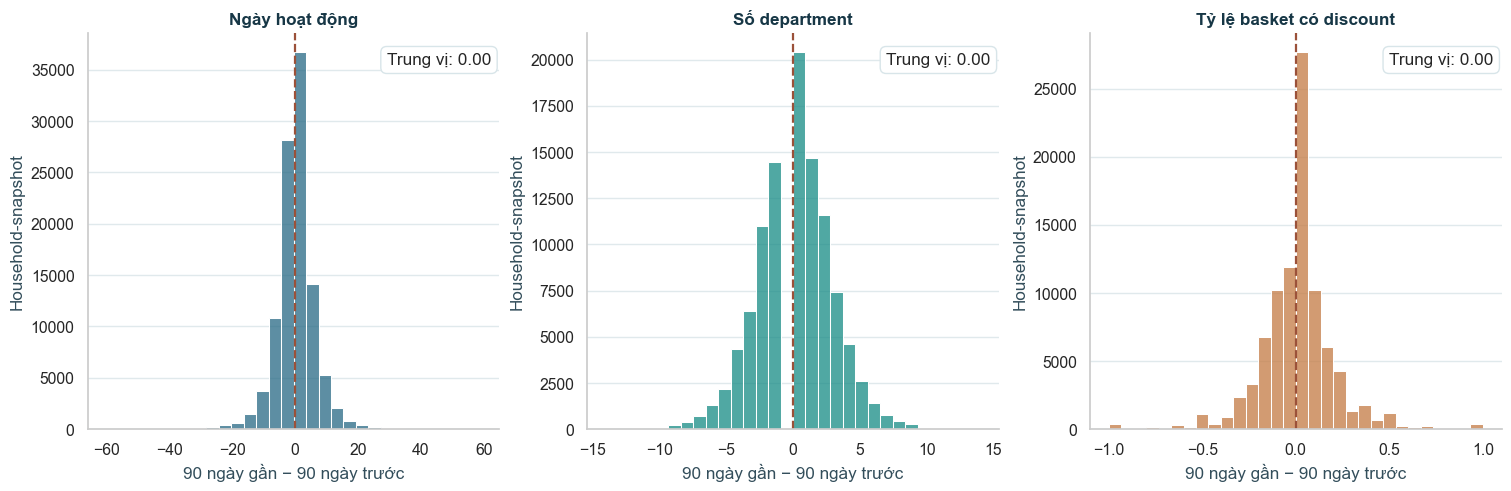

In [15]:
change_frames = []
for s in SNAPSHOTS:
    period_data = []
    for lo, hi in [(s-180, s-90), (s-90, s)]:
        bw = basket_history.loc[(basket_history.DAY > lo) & (basket_history.DAY <= hi)]
        dw = dept_tx.loc[(dept_tx.DAY > lo) & (dept_tx.DAY <= hi)]
        stats = bw.groupby('household_key').agg(active_days=('DAY', 'nunique'),
                    baskets=('BASKET_ID', 'size'), discounted=('has_discount', 'sum'))
        stats['departments'] = dw.groupby('household_key').DEPARTMENT.nunique()
        period_data.append(stats)
    eligible = first_day.index[first_day <= s-180]
    old = period_data[0].reindex(eligible).fillna(0)
    new = period_data[1].reindex(eligible).fillna(0)
    part = pd.DataFrame({'household_key': eligible, 'snapshot_day': s,
                         'active_days_change': new.active_days.to_numpy()-old.active_days.to_numpy(),
                         'departments_change': new.departments.to_numpy()-old.departments.to_numpy(),
                         'old_baskets': old.baskets.to_numpy(), 'new_baskets': new.baskets.to_numpy()})
    part['discount_share_change'] = (new.discounted / new.baskets.replace(0, np.nan)).to_numpy() - (old.discounted / old.baskets.replace(0, np.nan)).to_numpy()
    change_frames.append(part)
changes = pd.concat(change_frames, ignore_index=True)
print('Household-snapshot đủ 180 ngày:', len(changes), '| Household:', changes.household_key.nunique())
print('Có basket ở cả hai cửa sổ:', changes.discount_share_change.notna().sum())
display(changes[['active_days_change','departments_change','discount_share_change']].describe().T)
fig,axes=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
for ax,col,title,color in zip(axes,['active_days_change','departments_change','discount_share_change'],
                              ['Ngày hoạt động','Số department','Tỷ lệ basket có discount'],
                              [EDA_COLORS['blue'],EDA_COLORS['teal'],EDA_COLORS['orange']]):
    values=changes[col].dropna()
    sns.histplot(x=values,bins=30,color=color,edgecolor=None,ax=ax)
    ax.axvline(0,color='#9b5139',linestyle='--',linewidth=1.6)
    ax.set(title=title,xlabel='90 ngày gần − 90 ngày trước',ylabel='Household-snapshot')
    ax.text(.98,.95,f'Trung vị: {values.median():.2f}',transform=ax.transAxes,ha='right',va='top',
            bbox={'boxstyle':'round,pad=.35','facecolor':'white','edgecolor':'#d8e5e9'})
    ax.grid(axis='x',visible=False);sns.despine(ax=ax)
plt.show()


**Kết quả:** Có 105.483 household-snapshot của 2.497 household đạt điều kiện 180 ngày; 92.426 snapshot có basket ở cả hai cửa sổ để tính chênh lệch discount. Trung vị chênh lệch số ngày hoạt động và số department đều bằng 0; khoảng tứ phân vị lần lượt là −3 đến +3 ngày và −2 đến +2 department.

**Cách diễn giải:** Giá trị dương nghĩa là đại lượng ở 90 ngày gần cutoff cao hơn giai đoạn trước. Đây là thay đổi quan sát được, không xác nhận thay đổi sở thích hay nguyên nhân. Hai cửa sổ liên tiếp và các snapshot lặp khiến nhiều quan sát phụ thuộc nhau; nên đọc thêm số household riêng biệt và tránh khái quát từ các nhóm nhỏ.

## 6.5. Tỷ lệ mua tiếp có ổn định theo thời gian?

Biểu đồ target theo snapshot đã xuất hiện ở mục 5.2; ở đây ta tách thêm theo mức activity, kèm quy mô nhóm, để xem tỷ lệ chung có che khuất khác biệt giữa các nhóm hay không. Chỉ sử dụng snapshot train; đường đánh dấu snapshot 271 vì cửa sổ nhãn chứa ngày bất thường 278.

,snapshot_day,activity_group,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,180,0,122,122,12,0.098361
1,180,1-3,475,475,85,0.178947
2,180,4-9,693,693,270,0.389610
3,180,10-18,678,678,430,0.634218
4,180,19+,526,526,469,0.891635
5,187,0,135,135,8,0.059259
6,187,1-3,468,468,81,0.173077
7,187,4-9,690,690,269,0.389855
8,187,10-18,656,656,444,0.676829
9,187,19+,545,545,484,0.888073


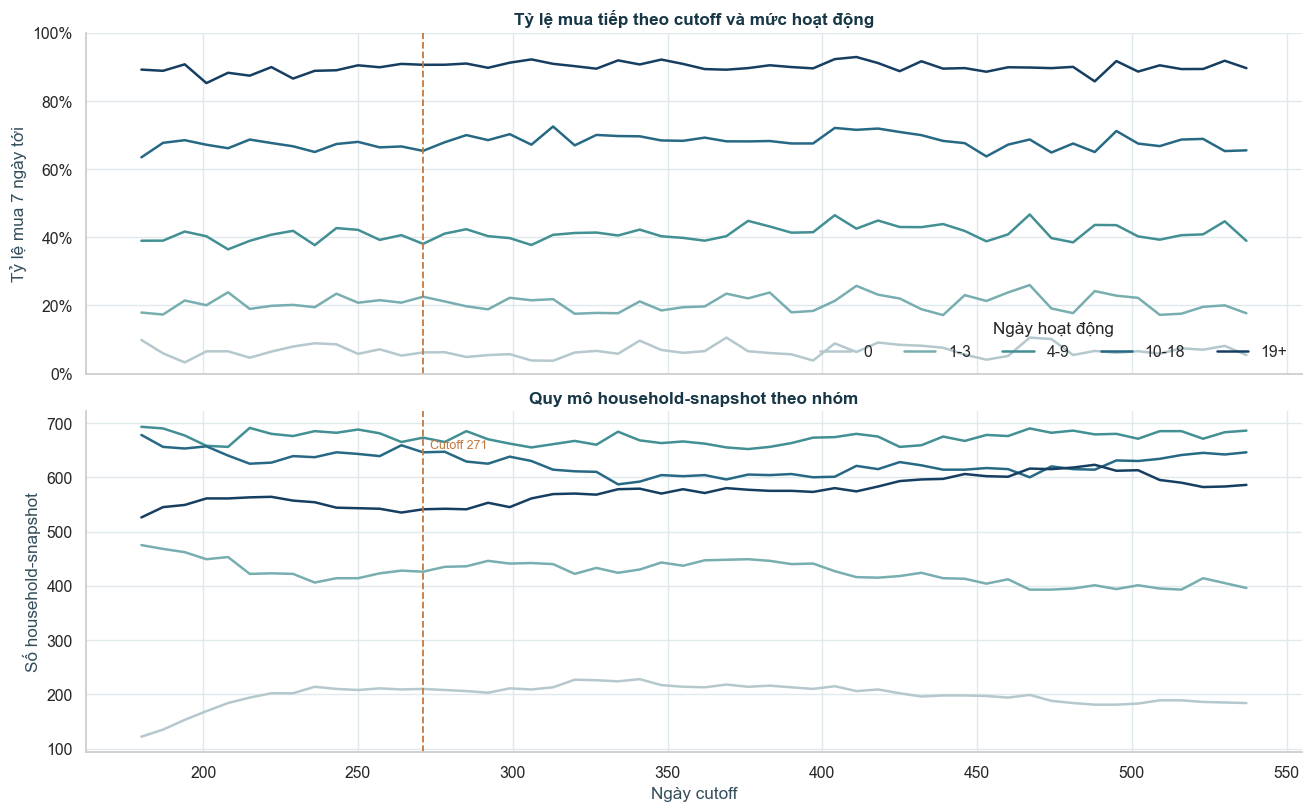

In [16]:
time_summary = group_summary(panel, ['snapshot_day', 'activity_group'])
display(time_summary.head(10))
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True,layout='constrained')
rate_wide=time_summary.pivot(index='snapshot_day',columns='activity_group',values='purchase_rate')
count_wide=time_summary.pivot(index='snapshot_day',columns='activity_group',values='household_snapshots')
for i,col in enumerate(rate_wide.columns):
    axes[0].plot(rate_wide.index,rate_wide[col],color=EDA_GROUP_COLORS[i],linewidth=1.8,label=str(col))
    axes[1].plot(count_wide.index,count_wide[col],color=EDA_GROUP_COLORS[i],linewidth=1.8)
for ax in axes:
    ax.axvline(271,color=EDA_COLORS['orange'],linestyle='--',linewidth=1.3)
    sns.despine(ax=ax)
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[0].set(title='Tỷ lệ mua tiếp theo cutoff và mức hoạt động',ylabel='Tỷ lệ mua 7 ngày tới',ylim=(0,1))
axes[0].legend(title='Ngày hoạt động',ncol=5,frameon=False,loc='lower right')
axes[1].set(title='Quy mô household-snapshot theo nhóm',xlabel='Ngày cutoff',ylabel='Số household-snapshot')
axes[1].annotate('Cutoff 271',xy=(271,.95),xycoords=('data','axes fraction'),xytext=(5,-8),textcoords='offset points',
                 color=EDA_COLORS['orange'],fontsize=9,va='top')
plt.show()


**Cách diễn giải:** Biến động có thể liên quan đến thay đổi hành vi, thành phần household hoặc chất lượng nguồn; biểu đồ không xác định nguyên nhân. Quy mô nhỏ làm tỷ lệ kém ổn định. Ngày 278 là bất thường đã quan sát, nhưng chưa có căn cứ xác định giao dịch thiếu hay kết luận nhãn sai.

Tiếp theo, ta đi sâu hơn vào fuel, coupon redemption và độ phủ demographic.

## 7. Fuel: khác biệt tổng thể có còn khi xét nhịp mua?

Ta so sánh các household-snapshot có và không có basket chứa `KIOSK-GAS` trong 90 ngày trước cutoff. Vì hộ mua thường xuyên có nhiều cơ hội phát sinh cả fuel lẫn basket tương lai, ta tiếp tục phân tầng theo số ngày hoạt động.

,fuel_90d,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,có fuel,35464,1204,26027,0.733899
1,không fuel,94370,2260,42517,0.450535


,activity_group,fuel_90d,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,không fuel,10357,670,688,0.066429
1,1-3,có fuel,1412,214,310,0.219547
2,1-3,không fuel,20696,1277,4241,0.204919
3,4-9,có fuel,5844,563,2448,0.418891
4,4-9,không fuel,29156,1633,11935,0.409350
5,10-18,có fuel,11139,785,7832,0.703115
6,10-18,không fuel,21375,1317,14259,0.667088
7,19+,có fuel,17069,692,15437,0.904388
8,19+,không fuel,12786,673,11394,0.891131


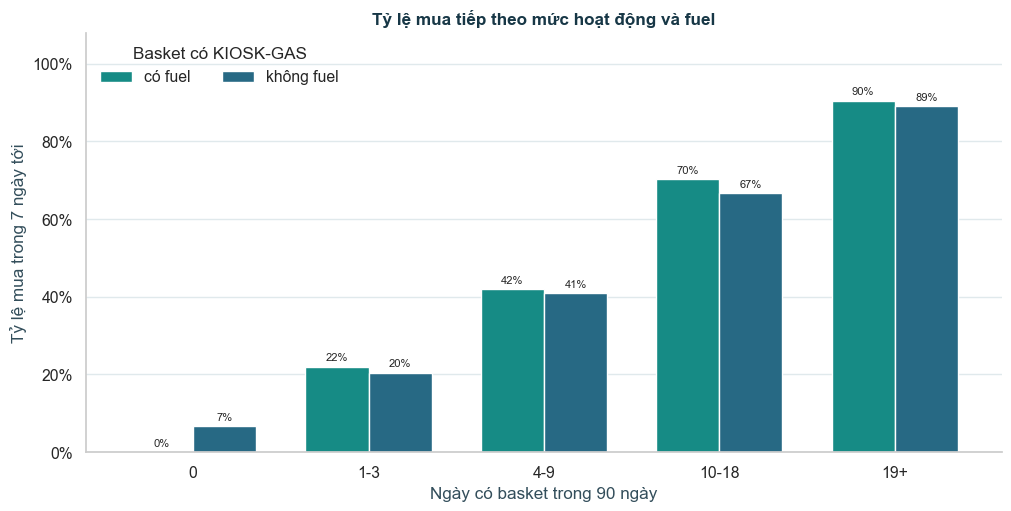

In [17]:
panel['fuel_90d'] = np.where(panel.fuel_basket_90d > 0, 'có fuel', 'không fuel')
fuel_overall = group_summary(panel, ['fuel_90d'])
fuel_strata = group_summary(panel, ['activity_group','fuel_90d'])
display(fuel_overall)
display(fuel_strata)
fuel_pivot=fuel_strata.pivot(index='activity_group',columns='fuel_90d',values='purchase_rate')
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
fuel_pivot.plot.bar(ax=ax,rot=0,color=[EDA_COLORS['teal'],EDA_COLORS['blue']],width=.72)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(title='Tỷ lệ mua tiếp theo mức hoạt động và fuel',xlabel='Ngày có basket trong 90 ngày',
       ylabel='Tỷ lệ mua trong 7 ngày tới',ylim=(0,1.08))
for container in ax.containers:
    ax.bar_label(container,labels=[f'{x.get_height():.0%}' if np.isfinite(x.get_height()) else '' for x in container],padding=3,fontsize=8)
ax.legend(title='Basket có KIOSK-GAS',frameon=False,ncol=2,loc='upper left')
ax.grid(axis='x',visible=False);sns.despine(ax=ax);plt.show()


**Kết quả:** Tỷ lệ mua tiếp tổng thể là 73,39% ở nhóm có fuel và 45,05% ở nhóm không có fuel. Trong nhóm có 4–9 ngày hoạt động, hai tỷ lệ lần lượt là 41,89% và 40,93%; chênh lệch thu hẹp so với so sánh tổng thể.

**Ý nghĩa:** Một phần khác biệt thô đi cùng khác biệt về tần suất hoạt động. Phân tầng đơn giản chưa kiểm soát mọi yếu tố, vì vậy kết quả không chứng minh fuel gây ra hay không gây ra mua hàng. Cùng cách thận trọng đó được áp dụng cho coupon ở phần tiếp theo.

## 8. Coupon: tín hiệu khuyến mại có đủ mạnh để diễn giải?

Coupon discount ghi trong transaction và redemption ghi ở bảng coupon là hai tín hiệu khác nhau. Ta xét từng tín hiệu trong `(s-90, s]`, cùng tỷ lệ mua tiếp và quy mô nhóm. Cả hai không mô tả đầy đủ việc household đã được tiếp xúc với campaign.

In [18]:
panel['coupon_discount_90d'] = np.where(panel.coupon_basket_90d > 0, 'có discount', 'không discount')
display(group_summary(panel, ['coupon_discount_90d']))
display(group_summary(panel, ['activity_group','coupon_discount_90d']))
redemption_days = {hh: np.sort(group.DAY.to_numpy()) for hh, group in redemption.groupby('household_key')}
flags = np.zeros(len(panel), dtype=bool)
for household, indices in panel.groupby('household_key').groups.items():
    observed = redemption_days.get(household)
    if observed is None:
        continue
    cutoffs = panel.loc[indices, 'snapshot_day'].to_numpy()
    flags[np.asarray(indices)] = (np.searchsorted(observed, cutoffs, side='right') >
                                  np.searchsorted(observed, cutoffs - 90, side='right'))
panel['redemption_90d'] = np.where(flags, 'có redemption', 'không redemption')
display(group_summary(panel, ['redemption_90d']))
redemption_strata = group_summary(panel, ['activity_group','redemption_90d'])
display(redemption_strata)

,coupon_discount_90d,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,có discount,44616,1666,32312,0.724224
1,không discount,85218,2319,36232,0.425168


,activity_group,coupon_discount_90d,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,không discount,10357,670,688,0.066429
1,1-3,có discount,1912,306,473,0.247385
2,1-3,không discount,20196,1262,4078,0.201921
3,4-9,có discount,8776,836,3984,0.453965
4,4-9,không discount,26224,1605,10399,0.396545
5,10-18,có discount,14763,1062,10390,0.703786
6,10-18,không discount,17751,1306,11701,0.659174
7,19+,có discount,19165,853,17465,0.911297
8,19+,không discount,10690,753,9366,0.876146


,redemption_90d,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,có redemption,4145,316,3501,0.844632
1,không redemption,125689,2498,65043,0.517492


,activity_group,redemption_90d,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,không redemption,10357,670,688,0.066429
1,1-3,có redemption,9,1,4,0.444444
2,1-3,không redemption,22099,1296,4547,0.205756
3,4-9,có redemption,321,50,155,0.482866
4,4-9,không redemption,34679,1757,14228,0.410277
5,10-18,có redemption,1265,156,1000,0.790514
6,10-18,không redemption,31249,1615,21091,0.674934
7,19+,có redemption,2550,211,2342,0.918431
8,19+,không redemption,27305,1076,24489,0.896869


**Kết quả và giới hạn:** Cần đọc tỷ lệ cùng số household-snapshot và số household riêng biệt. Chẳng hạn, nhóm có redemption và 1–3 ngày hoạt động chỉ gồm 9 household-snapshot từ một household; tỷ lệ của nhóm này không đủ để khái quát cho các hộ khác.

Coupon xuất hiện cùng giao dịch không chứng minh coupon tạo ra giao dịch tăng thêm. Ngoài hành vi và khuyến mại, dữ liệu còn có demographic, nhưng trước hết cần hiểu nhóm nào thực sự có hồ sơ.

## 9. Demographic: hồ sơ có đại diện cho toàn bộ household?

Chỉ 801 trong 2.500 household có bản ghi demographic. Ta so sánh nhóm có và không có hồ sơ để xem độ phủ này liên hệ thế nào với nhịp mua và target. Trạng thái có hồ sơ lấy từ file hiện tại; chưa xác nhận thông tin đã sẵn có tại từng cutoff lịch sử.

In [19]:
panel['demographic_record'] = np.where(panel.household_key.isin(demo.household_key), 'có hồ sơ', 'không hồ sơ')
display(group_summary(panel, ['demographic_record']))
display(group_summary(panel, ['activity_group','demographic_record']))

,demographic_record,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,có hồ sơ,41652,801,31908,0.766062
1,không hồ sơ,88182,1697,36636,0.415459


,activity_group,demographic_record,household_snapshots,unique_households,positive_snapshots,purchase_rate
0,0,có hồ sơ,495,48,50,0.101010
1,0,không hồ sơ,9862,622,638,0.064693
2,1-3,có hồ sơ,1354,139,438,0.323486
3,1-3,không hồ sơ,20754,1157,4113,0.198179
4,4-9,có hồ sơ,6508,413,3586,0.551014
5,4-9,không hồ sơ,28492,1349,10797,0.378948
6,10-18,có hồ sơ,15066,645,11147,0.739878
7,10-18,không hồ sơ,17448,977,10944,0.627235
8,19+,có hồ sơ,18229,595,16687,0.915410
9,19+,không hồ sơ,11626,490,10144,0.872527


**Kết quả:** Tỷ lệ mua tiếp ở nhóm có hồ sơ và không có hồ sơ lần lượt khoảng 76,61% và 41,55% trên các household-snapshot được khảo sát. Chênh lệch này có thể liên quan đến hành vi và cách chọn mẫu; các snapshot của cùng hộ cũng không độc lập.

**Ý nghĩa:** Không xem sự hiện diện của hồ sơ là nguyên nhân mua hàng. Cần kiểm tra thời điểm thu thập và khả năng thiên lệch lựa chọn trước khi sử dụng demographic cho dự báo. Cuối cùng, ta quay lại hai ngày bất thường để xác định phạm vi phân tích có thể chịu ảnh hưởng.

## 10. Hai ngày bất thường có thể ảnh hưởng đến những quan sát nào?

Ngày 278 và 643 mỗi ngày chỉ có một basket. Để đánh giá phạm vi cần kiểm tra thêm, ta đếm các snapshot có cửa sổ nhãn hoặc cửa sổ lịch sử chứa một trong hai ngày này. Đây là số quan sát *có khả năng* chịu ảnh hưởng, không phải số nhãn sai; nguyên nhân và mức độ thiếu dữ liệu chưa được xác minh. Cell chỉ dùng thời gian và eligibility, không sử dụng nhãn test.

In [20]:
all_snapshots = list(range(180, 699, 7))
first_observed = basket.groupby('household_key').DAY.min()
def partition(day):
    if 180 <= day <= 537:
        return 'train'
    if 551 <= day <= 621:
        return 'validation'
    if 635 <= day <= 698:
        return 'test'
    return 'embargo'
impact_records = []
for anomaly_day in (278, 643):
    for cutoff in all_snapshots:
        label_hit = cutoff < anomaly_day <= cutoff + HORIZON
        history_hit = cutoff - 90 < anomaly_day <= cutoff
        if label_hit or history_hit:
            impact_records.append({'ngày bất thường': anomaly_day, 'snapshot': cutoff,
                                   'phân vùng': partition(cutoff),
                                   'household đủ điều kiện': int((first_observed <= cutoff).sum()),
                                   'trong nhãn 7 ngày': label_hit,
                                   'trong lịch sử 90 ngày': history_hit})
impact = pd.DataFrame(impact_records)
display(impact.loc[impact['trong nhãn 7 ngày']])
display(impact.groupby(['ngày bất thường','phân vùng'], sort=False)
        .agg(snapshot_nhãn=('trong nhãn 7 ngày','sum'),
             snapshot_lịch_sử_90d=('trong lịch sử 90 ngày','sum')).reset_index())
print('Số household-snapshot nhãn bị chạm tới:',
      int(impact.loc[impact['trong nhãn 7 ngày'], 'household đủ điều kiện'].sum()))

,ngày bất thường,snapshot,phân vùng,household đủ điều kiện,trong nhãn 7 ngày,trong lịch sử 90 ngày
0,278,271,train,2496,True,False
14,643,642,test,2499,True,False


,ngày bất thường,phân vùng,snapshot_nhãn,snapshot_lịch_sử_90d
0,278,train,1,13
1,643,test,1,8


Số household-snapshot nhãn bị chạm tới: 4995


**Kết quả:** Cửa sổ nhãn của snapshot 271 chứa ngày 278, với 2.496 household đủ điều kiện trong train; snapshot 642 chứa ngày 643, với 2.499 household đủ điều kiện trong test. Đối với cửa sổ lịch sử 90 ngày, có 13 snapshot train và 8 snapshot test chứa một trong hai ngày bất thường.

**Ý nghĩa:** Một ngày ít giao dịch có thể liên quan đến cả nhãn lẫn lịch sử dùng để mô tả hành vi; lịch sử tích lũy dài hơn có thể chịu ảnh hưởng lâu hơn. Chưa có căn cứ khẳng định nhãn sai hay tự động xóa dữ liệu. Khi đánh giá mô hình, cần thiết kế phân tích độ nhạy riêng cho các cửa sổ nhãn và lịch sử, rồi diễn giải kết quả theo giới hạn này.

## 11. RFM: gần đây, thường xuyên và giá trị giao dịch

Các phần trước cho thấy recency và nhịp mua liên hệ với việc mua tiếp. Bây giờ ta đặt chúng cùng giá trị giao dịch trong một khung RFM để hiểu sự khác biệt giữa các household — **chưa tạo phân khúc hay feature mới cho mô hình**.

Chọn **cutoff 537**, cutoff cuối của train EDA: mỗi household đủ điều kiện xuất hiện đúng một lần. `R` là số ngày từ basket gần nhất đến cutoff; `F` là số basket trong 90 ngày; `M` là tổng `SALES_VALUE` trong 90 ngày. `M` là số tiền retailer nhận theo nguồn, không phải lợi nhuận hay giá trị vòng đời. Basket fuel và basket zero-sales vẫn được giữ theo định nghĩa target.

Khoảng F/M là `(447, 537]`; R có thể dùng lần mua trước cửa sổ này. Nhãn 7 ngày tiếp theo chỉ dùng để mô tả kết quả, không đưa vào tính RFM. Các khoảng 90 ngày là lựa chọn phân tích, chưa chứng minh là tối ưu. Hộ có ít hơn 90 ngày từ lần xuất hiện đầu tiên được đánh dấu; thời gian từ lần đầu quan sát không xác nhận dữ liệu đầy đủ.

In [21]:
rfm_cutoff = 537
rfm_history = basket.loc[(basket.DAY > rfm_cutoff-90) & (basket.DAY <= rfm_cutoff)]
rfm_eligible = panel.loc[panel.snapshot_day.eq(rfm_cutoff),
                         ['household_key','recency_days','target_any_basket']].copy()
assert rfm_eligible.household_key.is_unique
rfm_stats = (rfm_history.groupby('household_key')
             .agg(F_baskets_90d=('BASKET_ID','size'), M_sales_90d=('sales','sum'),
                  active_days_90d=('DAY','nunique')))
rfm = rfm_eligible.merge(rfm_stats,on='household_key',how='left',validate='one_to_one')
for col in ['F_baskets_90d','M_sales_90d','active_days_90d']:
    rfm[col] = rfm[col].fillna(0)
rfm = rfm.rename(columns={'recency_days':'R_recency_days'})
rfm['observed_days_inclusive'] = rfm_cutoff - rfm.household_key.map(first_day) + 1
assert len(rfm)==len(rfm_eligible) and rfm.R_recency_days.ge(0).all()
assert (rfm.active_days_90d <= rfm.F_baskets_90d).all()
assert int(rfm.F_baskets_90d.sum()) == len(rfm_history)
print('Household tại cutoff:',len(rfm),'| Hộ chưa đủ 90 ngày từ lần đầu ghi nhận:',
      int(rfm.observed_days_inclusive.lt(90).sum()))
print('Không có basket trong 90 ngày:',int(rfm.F_baskets_90d.eq(0).sum()),
      '| Có basket nhưng tổng sales = 0:',int((rfm.F_baskets_90d.gt(0)&rfm.M_sales_90d.eq(0)).sum()))
display(rfm[['R_recency_days','F_baskets_90d','M_sales_90d','active_days_90d']]
        .describe(percentiles=[.25,.5,.75,.9,.99]).T)

Household tại cutoff: 2498 | Hộ chưa đủ 90 ngày từ lần đầu ghi nhận: 0
Không có basket trong 90 ngày: 184 | Có basket nhưng tổng sales = 0: 0


,count,mean,std,min,25%,50%,75%,90%,99%,max
R_recency_days,2498.0,26.919135,66.122869,0.0,1.00,5.00,19.00,65.000,417.0300,507.00
F_baskets_90d,2498.0,15.703763,19.192205,0.0,4.00,10.00,21.00,35.000,98.0300,204.00
M_sales_90d,2498.0,452.999568,531.667206,0.0,85.81,272.38,640.04,1137.231,2331.6263,7088.86
active_days_90d,2498.0,12.740592,12.367259,0.0,4.00,9.00,18.00,29.000,56.0300,79.00


### 11.1. Phân bố R, F và M

Ba biểu đồ bao gồm mọi household đủ điều kiện. Để nhìn phần lớn phân bố, trục được **chặn tại phân vị 99%**: giá trị lớn hơn được dồn vào cột cuối, không xóa quan sát. Bảng thống kê phía trên giữ nguyên các giá trị gốc. Histogram không tự cho biết một household có giá trị kinh doanh cao hay thấp.

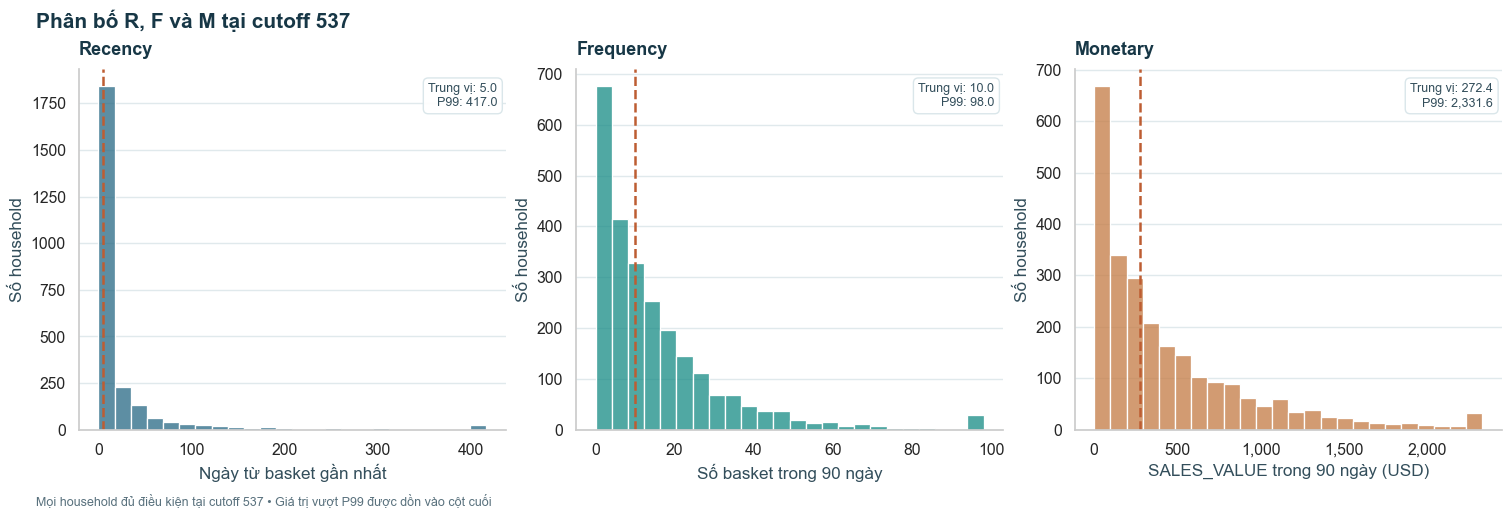

In [22]:
rfm_plot_cols=['R_recency_days','F_baskets_90d','M_sales_90d']
plot_titles=['Recency','Frequency','Monetary']
xlabels=['Ngày từ basket gần nhất','Số basket trong 90 ngày','SALES_VALUE trong 90 ngày (USD)']
colors=[EDA_COLORS['blue'],EDA_COLORS['teal'],EDA_COLORS['orange']]
fig,axes=plt.subplots(1,3,figsize=(15,4.8),layout='constrained')
fig.suptitle('Phân bố R, F và M tại cutoff 537',x=.02,ha='left',fontsize=15,fontweight='bold',color=EDA_COLORS['dark'])
for ax,col,title,xlabel,color in zip(axes,rfm_plot_cols,plot_titles,xlabels,colors):
    cap=rfm[col].quantile(.99);median=rfm[col].median()
    sns.histplot(x=rfm[col].clip(upper=cap),bins=24,ax=ax,color=color,edgecolor=None)
    ax.axvline(median,color='#bd5d32',linestyle='--',linewidth=1.8)
    ax.set_title(title,loc='left',fontsize=13,pad=10)
    ax.set(xlabel=xlabel,ylabel='Số household')
    ax.text(.98,.96,f'Trung vị: {median:,.1f}\nP99: {cap:,.1f}',transform=ax.transAxes,
            ha='right',va='top',fontsize=9,color='#334e5b',
            bbox=dict(boxstyle='round,pad=.4',facecolor='white',edgecolor='#d8e5e9',alpha=.95))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v,pos:f'{v:,.0f}'))
    ax.grid(axis='x',visible=False);sns.despine(ax=ax)
fig.text(.02,-.04,'Mọi household đủ điều kiện tại cutoff 537 • Giá trị vượt P99 được dồn vào cột cuối',fontsize=9,color=EDA_COLORS['muted'])
plt.show()


### 11.2. Recency và frequency mô tả target như thế nào?

Chia recency thành `0–7`, `8–30`, `31+` ngày và số **basket** trong 90 ngày thành `0`, `1–3`, `4–9`, `10+`. Mỗi ô thể hiện tỷ lệ household có basket trong ngày 538–544, kèm số hộ. Ô có dưới 30 hộ được để trống vì nhóm nhỏ, nhưng vẫn có trong bảng chi tiết. Các ngưỡng này phục vụ mô tả tại cutoff, không phải quy tắc phân khúc đã được tối ưu hay biến đưa vào model.

,R_group,F_group,households,buyers,purchase_rate
0,0–7,0,0,0,NaN
1,0–7,1–3,64,14,0.218750
2,0–7,4–9,288,120,0.416667
3,0–7,10+,1096,864,0.788321
4,8–30,0,0,0,NaN
5,8–30,1–3,119,22,0.184874
6,8–30,4–9,262,86,0.328244
7,8–30,10+,209,128,0.612440
8,31+,0,184,10,0.054348
9,31+,1–3,185,30,0.162162


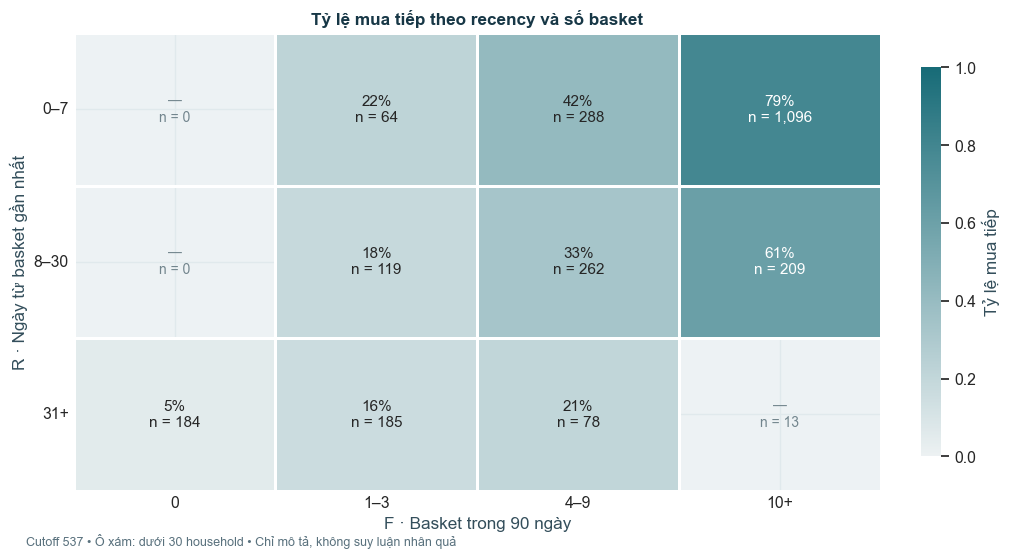

In [23]:
rfm['R_group']=pd.cut(rfm.R_recency_days,[-1,7,30,np.inf],labels=['0–7','8–30','31+'])
rfm['F_group']=pd.cut(rfm.F_baskets_90d,[-1,0,3,9,np.inf],labels=['0','1–3','4–9','10+'])
rf_cells=(rfm.groupby(['R_group','F_group'],observed=False)
          .agg(households=('household_key','size'),buyers=('target_any_basket','sum'),
               purchase_rate=('target_any_basket','mean')).reset_index())
display(rf_cells)
rf_rates=rf_cells.pivot(index='R_group',columns='F_group',values='purchase_rate')
rf_counts=rf_cells.pivot(index='R_group',columns='F_group',values='households')
fig,ax=plt.subplots(figsize=(10,5.3),layout='constrained')
shown=rf_rates.where(rf_counts>=30);labels=np.empty(shown.shape,dtype=object);ax.set_facecolor('#edf2f4')
for i in range(len(shown.index)):
    for j in range(len(shown.columns)):
        count=int(rf_counts.iloc[i,j]);value=shown.iloc[i,j]
        labels[i,j]=f'{value:.0%}\nn = {count:,}' if pd.notna(value) else ''
sns.heatmap(shown,annot=labels,fmt='',cmap=sns.light_palette('#176b77',as_cmap=True),
            vmin=0,vmax=1,linewidths=2,linecolor='white',ax=ax,
            annot_kws={'fontsize':11},cbar_kws={'label':'Tỷ lệ mua tiếp','shrink':.85})
for i in range(len(shown.index)):
    for j in range(len(shown.columns)):
        if rf_counts.iloc[i,j]<30:
            ax.text(j+.5,i+.5,f'—\nn = {int(rf_counts.iloc[i,j])}',ha='center',va='center',fontsize=10,color='#72858d')
ax.set(title='Tỷ lệ mua tiếp theo recency và số basket',xlabel='F · Basket trong 90 ngày',ylabel='R · Ngày từ basket gần nhất')
ax.tick_params(axis='both',length=0,labelrotation=0)
fig.text(.02,-.02,'Cutoff 537 • Ô xám: dưới 30 household • Chỉ mô tả, không suy luận nhân quả',fontsize=9,color=EDA_COLORS['muted'])
plt.show()


### 11.3. Monetary liên hệ thế nào với việc mua tiếp?

Tách hộ không có basket 90 ngày, hộ có basket nhưng tổng sales không dương, và các nhóm tứ phân vị `M` **trong số hộ có sales dương** tại cutoff 537. Ngưỡng được tính trên chính tập mô tả này, không áp dụng như ngưỡng feature khi dự báo. Báo đồng thời số household và tỷ lệ target; khác biệt có thể đi cùng tần suất, quy mô hộ hoặc yếu tố khác.

Mốc tứ phân vị sales dương: [9.90000e-01 1.17170e+02 3.16860e+02 6.78720e+02 7.08886e+03]


,households,buyers,purchase_rate,median_sales,median_baskets
M_group,,,,,
Không có basket,184,10,0.054348,0.000,0.0
Sales dương Q1,579,146,0.252159,54.930,3.0
Sales dương Q2,578,254,0.439446,206.195,8.0
Sales dương Q3,578,390,0.674740,462.205,15.0
Sales dương Q4,579,495,0.854922,1072.080,29.0


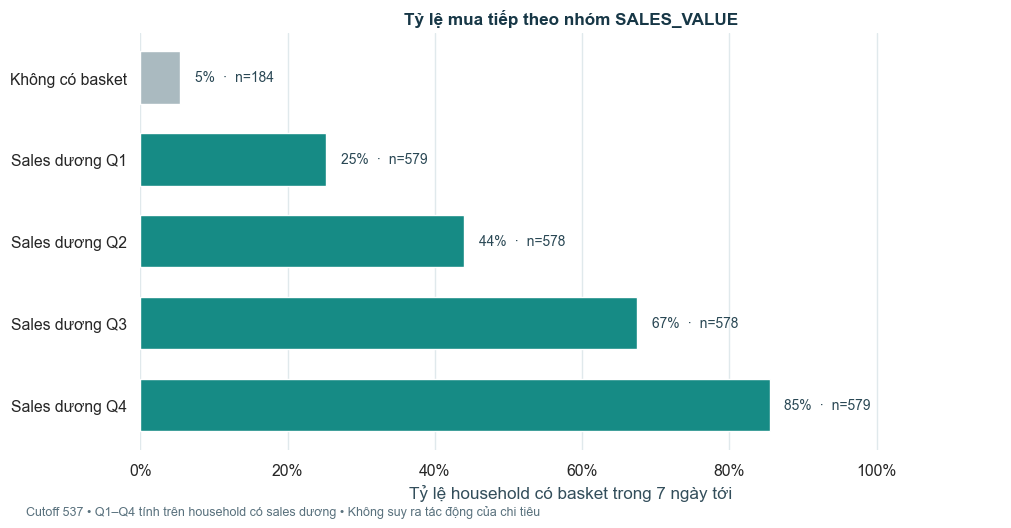

In [24]:
rfm['M_group']=np.where(rfm.F_baskets_90d.eq(0),'Không có basket',
                        np.where(rfm.M_sales_90d.le(0),'Có basket, sales ≤ 0','Sales dương'))
positive=rfm.M_sales_90d.gt(0) & rfm.F_baskets_90d.gt(0)
quartiles,monetary_edges=pd.qcut(rfm.loc[positive,'M_sales_90d'],q=4,duplicates='drop',retbins=True)
quartile_index=quartiles.cat.codes+1
rfm.loc[positive,'M_group']=['Sales dương Q'+str(i) for i in quartile_index]
monetary_summary=(rfm.groupby('M_group',dropna=False)
                  .agg(households=('household_key','size'),buyers=('target_any_basket','sum'),
                       purchase_rate=('target_any_basket','mean'),
                       median_sales=('M_sales_90d','median'),median_baskets=('F_baskets_90d','median')))
print('Mốc tứ phân vị sales dương:',np.round(monetary_edges,2))
display(monetary_summary)
order=[x for x in ['Không có basket','Có basket, sales ≤ 0','Sales dương Q1','Sales dương Q2','Sales dương Q3','Sales dương Q4'] if x in monetary_summary.index]
plot_data=monetary_summary.loc[order].reset_index()
colors=['#aabac0' if x in ('Không có basket','Có basket, sales ≤ 0') else EDA_COLORS['teal'] for x in order]
fig,ax=plt.subplots(figsize=(10,5),layout='constrained')
ax.barh(plot_data.M_group,plot_data.purchase_rate,color=colors,height=.64)
ax.invert_yaxis();ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set(title='Tỷ lệ mua tiếp theo nhóm SALES_VALUE',xlabel='Tỷ lệ household có basket trong 7 ngày tới',ylabel='',xlim=(0,1.17))
for i,row in plot_data.iterrows():
    ax.text(row.purchase_rate+.02,i,f'{row.purchase_rate:.0%}  ·  n={int(row.households):,}',va='center',fontsize=10,color='#294754')
ax.grid(axis='y',visible=False);sns.despine(ax=ax,left=True,bottom=True)
fig.text(.02,-.02,'Cutoff 537 • Q1–Q4 tính trên household có sales dương • Không suy ra tác động của chi tiêu',fontsize=9,color=EDA_COLORS['muted'])
plt.show()


**Cách diễn giải RFM:** Đọc R, F và M cùng nhau: recency mô tả lần mua gần nhất, frequency đếm basket và monetary mô tả giá trị retailer nhận được. `M` cao có thể đi cùng nhiều basket; bảng có median F để giúp nhận diện điều này, nhưng chưa loại bỏ các yếu tố gây nhiễu. Không gọi các nhóm là “khách hàng giá trị cao”, không suy ra lợi nhuận hoặc kết luận tác động nhân quả.

R/F/M là các nhóm thông tin ứng viên đã hiện diện trong 18 feature cơ bản của POC. Các nhóm mô tả ở đây không làm thay đổi feature, target hoặc pipeline hiện tại; muốn đánh giá chúng bổ sung giá trị cần một thí nghiệm tách nhóm và đánh giá theo thời gian.

## 12. Từ kết quả EDA đến quyết định chọn feature

Mỗi feature cần trả lời một câu hỏi về lịch sử của household tại cutoff. Quan sát EDA tạo cơ sở để đặt giả thuyết; nó không tự chứng minh feature gây ra mua hàng hoặc chắc chắn cải thiện mô hình.

| Quan sát / câu hỏi | Feature được đề xuất | Cách dùng và mức độ bằng chứng |
|---|---|---|
| Hộ mua gần đây có tỷ lệ mua tiếp cao hơn trong mẫu train | `recency_days` | Số ngày từ basket gần nhất đến cutoff. Baseline nhóm recency là mốc so sánh; kết quả là liên hệ mô tả. |
| Hộ hoạt động nhiều ngày có nhịp mua khác hộ ít hoạt động | `active_days_{w}d`, `baskets_{w}d` | Đếm ngày có basket và số basket trong `(s-w,s]`; một ngày có thể có nhiều basket. Các cửa sổ 7/30/90/180 là thiết kế ban đầu, không mặc định tối ưu. |
| Các chuyến mua có thể khác nhau về quy mô và giá trị | `line_items_{w}d`, `sales_{w}d` | Đếm dòng transaction và tổng `SALES_VALUE`. Đây là giả thuyết bổ trợ; chưa có ablation riêng chứng minh đóng góp của từng nhóm. `SALES_VALUE` không luôn bằng tiền khách thực trả. |
| Household xuất hiện dần trong dữ liệu | `observed_tenure_days` | Cutoff trừ ngày đầu được ghi nhận, không phải tuổi khách hàng ngoài đời. Cửa sổ nguồn đủ dài không đảm bảo hộ có đủ lịch sử. |
| Cùng recency có thể có ý nghĩa khác nhau theo nhịp mua riêng | Median/std gap 180 ngày, tỷ lệ recency/median và hai cờ đủ gap | Khoảng cách giữa các ngày có basket; thiếu nếu chưa đủ ngày mua. Thử nghiệm cho thấy Brier cải thiện trên bốn fold train nhưng lift không tăng đều; test đã được xem và hai phương án có kết quả gần nhau. |

**Không chọn chỉ vì hợp lý về trực giác:** trend, discount và thành phần basket đã được thử riêng; chưa cho cải thiện nhất quán để đưa vào pipeline chính. `QUANTITY` không được cộng xuyên department khi chưa rõ đơn vị; demographic/marketing chưa được dùng khi chưa xác minh availability tại cutoff.

Ví dụ tính tay, cách trả lời câu hỏi của mentor và đường dẫn kiểm chứng nằm trong [hướng dẫn báo cáo EDA và feature](../docs/HUONG_DAN_BAO_CAO_EDA_VA_FEATURE.md).

## 13. Kết luận và chuyển tiếp

Câu chuyện bắt đầu từ khả năng theo dõi hành vi theo household và thời gian. Các khóa được kiểm tra cho phép chuyển dòng sản phẩm thành basket; target đã thống nhất là **có bất kỳ basket nào trong 7 ngày sau cutoff**, bao gồm fuel, miscellaneous và basket có tổng sales bằng 0. Trong các snapshot được khảo sát, tỷ lệ target dương là 52,79%.

Lịch sử giao dịch cho thấy recency và nhịp mua có liên hệ với việc mua tiếp. Các khác biệt theo fuel, coupon và demographic cần được đặt cạnh tần suất hoạt động, độ phủ và số household riêng biệt; đây là kết quả mô tả, chưa chứng minh tác động nhân quả.

Các giới hạn cần mang sang giai đoạn tiếp theo: không tổng hợp `QUANTITY` xuyên department khi chưa rõ đơn vị; xác minh thời điểm sẵn có của demographic và marketing; khảo sát độ nhạy với hai ngày 278 và 643. Tập test đã được sử dụng trong các phân tích trước, vì vậy không nên coi đó là một tập đánh giá hoàn toàn chưa từng được xem xét.

**Trạng thái:** Data Understanding và EDA đã hoàn thành trong phạm vi dữ liệu hiện có. Bước tiếp theo là chuẩn bị dữ liệu và đánh giá mô hình theo thời gian, đồng thời kiểm tra các giới hạn trên; kết quả hiện tại không xác nhận dữ liệu nguồn hoàn chỉnh.